# CIC-IDS2017 Research Notebook — v4: Leakage-Safe Evaluation, Shortcut Ablation & Cross-Dataset Generalization

**Study type:** empirical comparative study of binary network-intrusion detection (Benign = 0, any attack = 1) on CIC-IDS2017, with an external test on CSE-CIC-IDS2018.

**Central question of v4:** *How much of the very high CIC-IDS2017 accuracy is real detection ability, and how much comes from duplicates, split leakage and dataset-specific shortcut features?*

## What changed from v3.1 (weakness → fix)

| # | Weakness found in v3.1 | Fix in v4 |
|---|---|---|
| 1 | Random row-level split; 9% duplicate rows, 8.6% of test vectors also in train | Exact duplicates and **conflicting-label rows removed**; split by **near-duplicate group**; hard `assert` of zero overlap; adversarial validation |
| 2 | Hyper-parameters tuned on only 25k rows (1.3% of training); CV choices disagreed with validation | Tuning on a **200k-row grouped, family-stratified subset** with `GroupKFold`; wider grids, no winners on the grid edge |
| 3 | Differences of 0.0002 declared "winners"; single seed, no uncertainty | **Multi-seed mean ± std**, bootstrap CI on MCC, champion chosen on validation only |
| 4 | `Destination Port` / window / header features suspected as shortcuts but never tested | **Shortcut ablation**: every model is run with *all features* and *no shortcuts* |
| 5 | Only binary metrics; 93% of attacks are 3 easy families | **Per-family recall**, per-file false-alarm rate, **leave-one-file-out** evaluation |
| 6 | Corrupt values (e.g. `Fwd Header Length` = −3.2e10) left in; `-1` sentinels unhandled | Documented cleaning: inf and impossible negatives → NaN, `-1` kept as sentinel |
| 7 | SHAP from 750 training rows, no stability, no control for RQ4 | SHAP on **validation** rows, **3 resamples + rank stability**, compared with permutation importance; feature-reduction compared against **ANOVA, gain and random** controls |
| 8 | Dead `Protocol` / chronological-split code; stale text (200k rows, 2.6 GB) | Removed. This CSV variant has **no Protocol, IP or timestamp**; stated explicitly |
| 9 | No conclusions, no dataset statistics tables | Full per-dataset **profile tables** and an auto-generated **findings section** |
| 10 | Threshold "tuning" with 4th-decimal gains | Fixed 0.5 threshold; threshold-free ROC-AUC / PR-AUC reported alongside |

## Data variant (read this)
The eight `*.pcap_ISCX.csv` files (79 columns) are the **MachineLearningCVE** variant. They contain 78 features plus `Label`, **no** Flow ID, IPs, Timestamp or Protocol. Consequences: session-level grouping and chronological splitting are impossible, so the grouping here is feature-based (near-duplicate keys) and **leave-one-file(day)-out** is used as the stronger realism check.

## How to run
1. Put the 2017 CSVs in `data/raw/` and (optionally) the 2018 *Processed Traffic Data for ML Algorithms* CSVs in `data/external/CSE-CIC-IDS2018/Processed Traffic Data for ML Algorithms/`. Or set the environment variables `CICIDS_RAW_2017`, `CICIDS_RAW_2018`, `CICIDS_OUT`.
2. Paths are found exactly like in v3.1 (walks up to `pyproject.toml`; `data/raw` and `data/external/CSE-CIC-IDS2018/Processed Traffic Data for ML Algorithms`). `uv add numpy pandas scipy scikit-learn matplotlib xgboost shap joblib` then **Restart & Run All**.
3. Quick check on a small sample: set `CICIDS_SMOKE=1`.
4. **Checkpoints:** profiles, tuning and final training are cached in `research_outputs_v4/cache/`. If the kernel is interrupted, Restart & Run All resumes from the last finished stage instead of starting over. Delete the `cache/` folder (or set `USE_CACHE = False`) to force a full recompute.

## 0. Configuration

In [1]:
import os, json, time, platform, warnings, re, hashlib
from pathlib import Path

SMOKE = os.environ.get("CICIDS_SMOKE", "0") == "1"          # tiny budgets for a quick end-to-end check


def find_project_root(start=None):
    """Same logic as v3.1: walk up from the working folder until pyproject.toml is found."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    print("WARNING: no pyproject.toml found above", current, "-> using the current folder as project root")
    return current


PROJECT_DIR = Path(os.environ["CICIDS_PROJECT_DIR"]) if os.environ.get("CICIDS_PROJECT_DIR") else find_project_root()
RAW_2017_DIR = Path(os.environ["CICIDS_RAW_2017"]) if os.environ.get("CICIDS_RAW_2017") else PROJECT_DIR / "data" / "raw"
RAW_2018_DIR = Path(os.environ["CICIDS_RAW_2018"]) if os.environ.get("CICIDS_RAW_2018") else (
    PROJECT_DIR / "data" / "external" / "CSE-CIC-IDS2018" / "Processed Traffic Data for ML Algorithms")
OUT_DIR = Path(os.environ["CICIDS_OUT"]) if os.environ.get("CICIDS_OUT") else PROJECT_DIR / "research_outputs_v4"
TABLES, FIGS, MODELS_DIR, CACHE_DIR = OUT_DIR / "tables", OUT_DIR / "figures", OUT_DIR / "models", OUT_DIR / "cache"
for d in (TABLES, FIGS, MODELS_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- path check: fail early with a clear message, never a confusing error later ----
print("PROJECT_DIR :", PROJECT_DIR)
print("2017 folder :", RAW_2017_DIR, "| exists:", RAW_2017_DIR.exists(),
      "| csv files:", len(list(RAW_2017_DIR.glob("*.csv"))) if RAW_2017_DIR.exists() else 0)
print("2018 folder :", RAW_2018_DIR, "| exists:", RAW_2018_DIR.exists(),
      "| csv files:", len(list(RAW_2018_DIR.rglob("*.csv"))) if RAW_2018_DIR.exists() else 0)
if not RAW_2017_DIR.exists() or not list(RAW_2017_DIR.rglob("*.csv")):
    raise FileNotFoundError(f"CIC-IDS2017 CSV files not found in {RAW_2017_DIR}. "
                            f"Put them there or set CICIDS_RAW_2017 to the folder that contains them.")

SEED = 42
SAMPLE_FRAC = 1.0                       # <1.0 only for debugging
NEAR_DECIMALS = 1                       # near-duplicate tolerance: signed-log value rounded to 1 decimal (~10%)
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)    # train / validation / test, split by GROUP not by row

TUNE_ROWS = 3_000 if SMOKE else 200_000          # grouped, family-stratified tuning subset
CV_FOLDS = 3
FINAL_SEEDS = [42, 43] if SMOKE else [42, 43, 44]
MAX_FINAL_TRAIN_ROWS = None                      # e.g. 600_000 if Random Forest is too slow; None = all
SHAP_SAMPLE = 500 if SMOKE else 2_000
PERM_SAMPLE = 2_000 if SMOKE else 20_000
SHAP_K_LIST = [5, 10, 20, 30]
REDUCTION_TRAIN_ROWS = 5_000 if SMOKE else 500_000
LOFO_TRAIN_ROWS = 5_000 if SMOKE else 300_000
N_BOOT = 100 if SMOKE else 300
DRIFT_PER_CLASS = 3_000 if SMOKE else 20_000
THRESHOLD = 0.5                                  # fixed on purpose: no threshold tuning
CODE_VERSION = "v4.1"                            # bump to invalidate old caches
USE_CACHE = True                                 # re-run after an interruption resumes from the last finished stage
SPLIT_REPEATS = [1] if SMOKE else [1, 2]         # extra random group-splits for the split-variance check
RUN_SPLIT_VARIANCE = True
XGB_DEVICE_REQUESTED = "cpu" if SMOKE else "cuda"
PROFILE_2018 = True
RUN_LOFO = True
RUN_EXTERNAL = RAW_2018_DIR.exists() and len(list(RAW_2018_DIR.rglob("*.csv"))) > 0

warnings.filterwarnings("ignore", category=UserWarning)
print("SMOKE:", SMOKE, "| 2017:", RAW_2017_DIR, "| 2018 found:", RUN_EXTERNAL, "| out:", OUT_DIR)

PROJECT_DIR : E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection
2017 folder : E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\data\raw | exists: True | csv files: 8
2018 folder : E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\data\external\CSE-CIC-IDS2018\Processed Traffic Data for ML Algorithms | exists: True | csv files: 10
SMOKE: False | 2017: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\data\raw | 2018 found: True | out: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\research_outputs_v4


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, sklearn
from IPython.display import display
from scipy.stats import ks_2samp, spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, matthews_corrcoef, roc_auc_score
from sklearn.model_selection import GroupKFold, ParameterGrid, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

try:
    import xgboost as xgb
    XGB_OK = True
except ImportError:
    XGB_OK = False
try:
    import shap
    SHAP_OK = True
except ImportError:
    SHAP_OK = False

pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 120)


def resolve_xgb_device(requested):
    """Explicit, recorded device choice: use CUDA only if it is really active, otherwise say so and use CPU."""
    if not XGB_OK:
        return None
    if requested == "cpu":
        return "cpu"
    try:
        probe = xgb.XGBClassifier(n_estimators=2, max_depth=2, tree_method="hist", device=requested, verbosity=0)
        probe.fit(np.random.rand(20, 2).astype("float32"), np.r_[np.zeros(10), np.ones(10)])
        assert re.search(r'"device"\s*:\s*"cuda', probe.get_booster().save_config())
        return requested
    except Exception as exc:
        print("CUDA not available -> XGBoost runs on CPU (recorded in the manifest):", repr(exc)[:120])
        return "cpu"


XGB_DEVICE = resolve_xgb_device(XGB_DEVICE_REQUESTED)
MODELS = ["lr", "rf", "xgb" if XGB_OK else "hgb"]
TREE_MODELS = [m for m in MODELS if m != "lr"]
print(f"sklearn {sklearn.__version__} | pandas {pd.__version__} | xgboost {XGB_OK} (device={XGB_DEVICE}) | shap {SHAP_OK}")
print("models:", MODELS)

e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sklearn 1.9.1 | pandas 3.1.1 | xgboost True (device=cuda) | shap True
models: ['lr', 'rf', 'xgb']


## 1. Helper library
Everything below is defined once and reused: canonical 77-feature schema, 2018→2017 column mapping, chunked reader, cleaning rules, duplicate hashing, metrics.

**Cleaning rules (documented decisions, not silent fixes)**
- `±inf → NaN` (they come from division by a zero duration in `Flow Bytes/s`, `Flow Packets/s`).
- Negative values → NaN for every feature that is physically non-negative (durations, IATs, header lengths, counts). These are CICFlowMeter overflow/timestamp bugs, e.g. `Fwd Header Length` = −3.2e10.
- `Init_Win_bytes_forward/backward` keep `-1`: it is a genuine "no data / no handshake" sentinel, not corruption.
- Rows are **never** deleted for being extreme: extreme flows can be real attacks.

In [3]:
import re
from pathlib import Path
from typing import Iterator

import numpy as np
import pandas as pd

SEED = 42

# --------------------------------------------------------------------------
# Canonical schema = CIC-IDS2017 "MachineLearningCVE" features
# (the duplicated 'Fwd Header Length.1' column is intentionally NOT included)
# --------------------------------------------------------------------------
CANONICAL_FEATURES = [
    "Destination Port", "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
    "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
    "Flow Bytes/s", "Flow Packets/s",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Fwd PSH Flags", "Bwd PSH Flags", "Fwd URG Flags", "Bwd URG Flags",
    "Fwd Header Length", "Bwd Header Length", "Fwd Packets/s", "Bwd Packets/s",
    "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std",
    "Packet Length Variance",
    "FIN Flag Count", "SYN Flag Count", "RST Flag Count", "PSH Flag Count", "ACK Flag Count",
    "URG Flag Count", "CWE Flag Count", "ECE Flag Count", "Down/Up Ratio",
    "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size",
    "Fwd Avg Bytes/Bulk", "Fwd Avg Packets/Bulk", "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk", "Bwd Avg Packets/Bulk", "Bwd Avg Bulk Rate",
    "Subflow Fwd Packets", "Subflow Fwd Bytes", "Subflow Bwd Packets", "Subflow Bwd Bytes",
    "Init_Win_bytes_forward", "Init_Win_bytes_backward", "act_data_pkt_fwd", "min_seg_size_forward",
    "Active Mean", "Active Std", "Active Max", "Active Min",
    "Idle Mean", "Idle Std", "Idle Max", "Idle Min",
]
assert len(CANONICAL_FEATURES) == 77, len(CANONICAL_FEATURES)

# 2018 header names that differ from the 2017 ones
ALIASES_2018 = {
    "Destination Port": ["Dst Port"], "Total Fwd Packets": ["Tot Fwd Pkts"],
    "Total Backward Packets": ["Tot Bwd Pkts"], "Total Length of Fwd Packets": ["TotLen Fwd Pkts"],
    "Total Length of Bwd Packets": ["TotLen Bwd Pkts"],
    "Fwd Packet Length Max": ["Fwd Pkt Len Max"], "Fwd Packet Length Min": ["Fwd Pkt Len Min"],
    "Fwd Packet Length Mean": ["Fwd Pkt Len Mean"], "Fwd Packet Length Std": ["Fwd Pkt Len Std"],
    "Bwd Packet Length Max": ["Bwd Pkt Len Max"], "Bwd Packet Length Min": ["Bwd Pkt Len Min"],
    "Bwd Packet Length Mean": ["Bwd Pkt Len Mean"], "Bwd Packet Length Std": ["Bwd Pkt Len Std"],
    "Flow Bytes/s": ["Flow Byts/s"], "Flow Packets/s": ["Flow Pkts/s"],
    "Fwd IAT Total": ["Fwd IAT Tot"], "Bwd IAT Total": ["Bwd IAT Tot"],
    "Fwd Header Length": ["Fwd Header Len"], "Bwd Header Length": ["Bwd Header Len"],
    "Fwd Packets/s": ["Fwd Pkts/s"], "Bwd Packets/s": ["Bwd Pkts/s"],
    "Min Packet Length": ["Pkt Len Min"], "Max Packet Length": ["Pkt Len Max"],
    "Packet Length Mean": ["Pkt Len Mean"], "Packet Length Std": ["Pkt Len Std"],
    "Packet Length Variance": ["Pkt Len Var"],
    "FIN Flag Count": ["FIN Flag Cnt"], "SYN Flag Count": ["SYN Flag Cnt"],
    "RST Flag Count": ["RST Flag Cnt"], "PSH Flag Count": ["PSH Flag Cnt"],
    "ACK Flag Count": ["ACK Flag Cnt"], "URG Flag Count": ["URG Flag Cnt"],
    "CWE Flag Count": ["CWE Flag Count"], "ECE Flag Count": ["ECE Flag Cnt"],
    "Average Packet Size": ["Pkt Size Avg"], "Avg Fwd Segment Size": ["Fwd Seg Size Avg"],
    "Avg Bwd Segment Size": ["Bwd Seg Size Avg"],
    "Fwd Avg Bytes/Bulk": ["Fwd Byts/b Avg"], "Fwd Avg Packets/Bulk": ["Fwd Pkts/b Avg"],
    "Fwd Avg Bulk Rate": ["Fwd Blk Rate Avg"], "Bwd Avg Bytes/Bulk": ["Bwd Byts/b Avg"],
    "Bwd Avg Packets/Bulk": ["Bwd Pkts/b Avg"], "Bwd Avg Bulk Rate": ["Bwd Blk Rate Avg"],
    "Subflow Fwd Packets": ["Subflow Fwd Pkts"], "Subflow Fwd Bytes": ["Subflow Fwd Byts"],
    "Subflow Bwd Packets": ["Subflow Bwd Pkts"], "Subflow Bwd Bytes": ["Subflow Bwd Byts"],
    "Init_Win_bytes_forward": ["Init Fwd Win Byts"], "Init_Win_bytes_backward": ["Init Bwd Win Byts"],
    "act_data_pkt_fwd": ["Fwd Act Data Pkts"], "min_seg_size_forward": ["Fwd Seg Size Min"],
}

# -1 is a legitimate "no data" sentinel for these two; every other feature is physically >= 0
SENTINEL_FEATURES = {"Init_Win_bytes_forward", "Init_Win_bytes_backward"}

# Features that act as dataset/testbed fingerprints rather than attack behaviour.
SHORTCUT_FEATURES = [
    "Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward",
    "Fwd Header Length", "Bwd Header Length", "min_seg_size_forward",
]


# --------------------------------------------------------------------------
# Schema mapping + chunked reading
# --------------------------------------------------------------------------
def norm_token(name: str) -> str:
    return re.sub(r"[^a-z0-9]+", "", str(name).casefold())


def build_column_map(raw_cols, aliases) -> dict:
    lookup = {}
    for c in raw_cols:
        lookup.setdefault(norm_token(c), []).append(c)
    mapping = {}
    for feat in CANONICAL_FEATURES:
        tokens = [norm_token(feat)] + [norm_token(a) for a in aliases.get(feat, [])]
        hits = list(dict.fromkeys(r for t in tokens for r in lookup.get(t, [])))
        if len(hits) == 1:
            mapping[feat] = hits[0]
        elif len(hits) > 1:
            raise ValueError(f"Ambiguous mapping for '{feat}': {hits}")
    return mapping


def clean_label(s: pd.Series) -> pd.Series:
    """Strip, and replace the broken non-ASCII dash in 'Web Attack - ...' labels."""
    s = s.astype("string").str.strip()
    return s.str.replace(r"[^\x20-\x7E]+", "-", regex=True)


def list_csvs(folder: str | Path) -> list[Path]:
    folder = Path(folder)
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder.resolve()}")
    files = sorted(folder.glob("*.csv")) or sorted(folder.rglob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No CSV files in {folder.resolve()}. Contents: {[p.name for p in folder.iterdir()][:10]}")
    return files


def iter_chunks(files, dataset: str, chunksize: int = 500_000,
                sample_frac: float = 1.0, seed: int = SEED
                ) -> Iterator[tuple[pd.DataFrame, pd.Series, str]]:
    """Yield (X_raw float32 canonical columns, label str, file name).

    X_raw is NOT cleaned (inf / negatives preserved) so audits can count them.
    Repeated header rows and blank labels are dropped.
    """
    aliases = ALIASES_2018 if dataset == "2018" else {}
    rng = np.random.default_rng(seed)
    for path in files:
        header = pd.read_csv(path, nrows=0, encoding="latin1").columns.tolist()
        cmap = build_column_map(header, aliases)
        missing = [f for f in CANONICAL_FEATURES if f not in cmap]
        if missing:
            raise ValueError(f"{path.name}: {len(missing)} features missing, e.g. {missing[:5]}")
        label_cols = [c for c in header if norm_token(c) == "label"]
        if len(label_cols) != 1:
            raise ValueError(f"{path.name}: expected one Label column, got {label_cols}")
        lab_col = label_cols[0]
        usecols = list(cmap.values()) + [lab_col]
        for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize,
                                 encoding="latin1", low_memory=False):
            lab = chunk[lab_col].astype("string").str.strip()
            ok = lab.notna() & lab.ne("") & lab.str.casefold().ne("label")
            if sample_frac < 1.0:
                ok &= pd.Series(rng.random(len(chunk)) < sample_frac, index=chunk.index)
            chunk, lab = chunk.loc[ok], clean_label(lab.loc[ok])
            if chunk.empty:
                continue
            X = chunk[[cmap[f] for f in CANONICAL_FEATURES]].copy()
            X.columns = CANONICAL_FEATURES
            X = X.apply(pd.to_numeric, errors="coerce").astype("float32")
            yield X.reset_index(drop=True), lab.reset_index(drop=True), path.name


def to_binary(label: pd.Series) -> np.ndarray:
    return (label.str.casefold() != "benign").astype("int8").to_numpy()


# --------------------------------------------------------------------------
# Cleaning
# --------------------------------------------------------------------------
def clean_features(X: pd.DataFrame) -> pd.DataFrame:
    """inf -> NaN; negative values -> NaN except the -1 sentinels.

    CICFlowMeter has integer-overflow / timestamp bugs that produce impossible
    negative durations, IATs and header lengths (e.g. Fwd Header Length -3.2e10).
    Those are corrupt measurements, not information, so they become NaN
    (the model/imputer then treats them as missing).
    """
    A = X.to_numpy(dtype="float64", copy=True)
    A[~np.isfinite(A)] = np.nan
    for j, col in enumerate(X.columns):
        if col not in SENTINEL_FEATURES:
            A[A[:, j] < 0, j] = np.nan
    return pd.DataFrame(A.astype("float32"), columns=X.columns)


# --------------------------------------------------------------------------
# Hashing for duplicate detection
# --------------------------------------------------------------------------
def row_hash(X: pd.DataFrame) -> np.ndarray:
    return pd.util.hash_pandas_object(X, index=False).to_numpy(dtype="uint64")


def near_key(X: pd.DataFrame, decimals: int = 1) -> np.ndarray:
    """Hash of the row after a signed-log transform and rounding.

    Two flows whose every feature agrees to ~10% (decimals=1) get the same key,
    so near-copies of the same attack session fall in the same group.
    """
    A = X.to_numpy(dtype="float64")
    T = np.round(np.sign(A) * np.log1p(np.abs(A)), decimals) + 0.0   # +0.0 removes -0.0
    return row_hash(pd.DataFrame(T, columns=X.columns))


# --------------------------------------------------------------------------
# Metrics
# --------------------------------------------------------------------------
def _mcc_from_counts(tn, fp, fn, tp):
    # float arithmetic on purpose: with ~400k rows the int64 product of the four marginals overflows
    tn, fp, fn, tp = float(tn), float(fp), float(fn), float(tp)
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return (tp * tn - fp * fn) / den if den > 0 else 0.0


def binary_metrics(y, pred, prob=None) -> dict:
    from sklearn.metrics import average_precision_score, roc_auc_score
    y, pred = np.asarray(y, dtype=np.int8), np.asarray(pred, dtype=np.int8)
    tn, fp, fn, tp = np.bincount(2 * y + pred, minlength=4)
    out = {
        "n": len(y), "n_attack": int(y.sum()),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
        "f1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
        "mcc": _mcc_from_counts(tn, fp, fn, tp),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }
    if prob is not None and len(np.unique(y)) == 2:
        out["roc_auc"] = roc_auc_score(y, prob)
        out["pr_auc"] = average_precision_score(y, prob)
    return out


def bootstrap_mcc_ci(y, pred, n_boot: int = 200, seed: int = SEED) -> tuple[float, float]:
    y, pred = np.asarray(y, dtype=np.int8), np.asarray(pred, dtype=np.int8)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        tn, fp, fn, tp = np.bincount(2 * y[idx] + pred[idx], minlength=4)
        vals.append(_mcc_from_counts(tn, fp, fn, tp))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

In [4]:
# ---- extra helpers used by the experiment ---------------------------------------------------------
def signed_log1p(A):
    A = np.asarray(A, dtype="float64")
    return np.sign(A) * np.log1p(np.abs(A))


def cap_rows(idx, strata, cap, seed=SEED):
    """Random subset of `idx` (positions) that keeps the stratum (attack-family) proportions."""
    idx = np.asarray(idx)
    if not cap or len(idx) <= cap:
        return idx
    s = pd.Series(np.asarray(strata)[idx], index=idx)
    frac = cap / len(idx)
    return s.groupby(s.values, group_keys=False).apply(lambda g: g.sample(frac=frac, random_state=seed)).index.to_numpy()


def per_family_recall(labels, pred):
    df = pd.DataFrame({"label": np.asarray(labels), "hit": np.asarray(pred)})
    df = df[df["label"].astype(str).str.casefold() != "benign"]
    r = df.groupby("label")["hit"].agg(support="size", detected="sum")
    r["recall"] = (r["detected"] / r["support"]).round(4)
    return r.sort_values("recall")


def per_file_fpr(meta_e, pred):
    df = pd.DataFrame({"file": meta_e["file"].to_numpy(), "y": meta_e["y"].to_numpy(), "pred": np.asarray(pred)})
    b = df[df.y == 0].groupby("file")["pred"].agg(benign_rows="size", false_alarms="sum")
    b["fpr"] = (b["false_alarms"] / b["benign_rows"]).round(5)
    return b


def save(df, name):
    path = TABLES / name
    df.to_csv(path)
    return path


def cache_key(*parts):
    return hashlib.md5("|".join(map(str, parts)).encode()).hexdigest()[:10]


def cached(name, key, builder):
    """Run `builder()` once; later runs (same key) load the saved result. Protects against kernel interruptions."""
    path = CACHE_DIR / f"{name}_{key}.joblib"
    if USE_CACHE and path.exists():
        print(f"[cache] loaded '{name}' from {path.name}")
        return joblib.load(path)
    obj = builder()
    joblib.dump(obj, path, compress=3)
    return obj


def files_signature(files):
    return [(p.name, p.stat().st_size) for p in files]

## 2. Dataset profile — statistics for every dataset
For each dataset: info, rows per file, label distribution, per-feature missing / inf / negative / zero counts, ranges, skew, constant features, and duplicates (exact **and** near), conflicting labels, cross-file duplicates. Only 64-bit row hashes are kept in memory, so the 16M-row 2018 data is feasible.

In [5]:
def duplicate_report(exact, near, y, fid, file_names):
    n = len(exact)
    df = pd.DataFrame({"h": exact, "nk": near, "y": y, "f": fid})
    rows = []
    add = lambda m, v: rows.append({"metric": m, "value": v})
    add("rows", n)
    for tag, col in [("exact", "h"), ("near", "nk")]:
        g = df.groupby(col, sort=False).agg(size=("y", "size"), ymin=("y", "min"), ymax=("y", "max"),
                                            fmin=("f", "min"), fmax=("f", "max"))
        same = df.duplicated([col, "y"]).to_numpy()
        conflict, cross = g[g.ymin != g.ymax], g[g.fmin != g.fmax]
        if tag == "exact":
            conflict_hashes = conflict.index.to_numpy(dtype="uint64")
        add(f"{tag}: unique vectors", len(g))
        add(f"{tag}: duplicate rows (all but first copy)", n - len(g))
        add(f"{tag}: duplicate rows %", round(100 * (n - len(g)) / n, 3))
        add(f"{tag}: duplicate rows among BENIGN", int(same[y == 0].sum()))
        add(f"{tag}: duplicate rows among ATTACK", int(same[y == 1].sum()))
        add(f"{tag}: largest group", int(g["size"].max()))
        add(f"{tag}: CONFLICTING-label groups", len(conflict))
        add(f"{tag}: rows in conflicting groups", int(conflict["size"].sum()))
        add(f"{tag}: groups spanning >1 file", len(cross))
        add(f"{tag}: rows in cross-file groups", int(cross["size"].sum()))
    within = df.duplicated(["h", "f"]).to_numpy()
    pf = pd.DataFrame({"f": fid, "dup": within}).groupby("f")["dup"].agg(["size", "sum"])
    pf.columns = ["rows", "within_file_duplicate_rows"]
    pf["pct"] = (100 * pf["within_file_duplicate_rows"] / pf["rows"]).round(3)
    pf.index = [file_names[i] for i in pf.index]
    return pd.DataFrame(rows).set_index("metric"), pf, conflict_hashes


def profile_dataset(name, files, sample_frac=0.05, chunksize=500_000):
    nf = len(CANONICAL_FEATURES)
    rng = np.random.default_rng(SEED)
    n_rows = 0
    c_nan, c_inf, c_neg, c_m1, c_zero, c_fin = (np.zeros(nf, np.int64) for _ in range(6))
    s1, s2 = np.zeros(nf), np.zeros(nf)
    mn, mx = np.full(nf, np.inf), np.full(nf, -np.inf)
    samples, hashes, nears, ys, fids, names = [], [], [], [], [], []
    label_counts = {}
    for Xr, lab, fname in iter_chunks(files, name, chunksize):
        if fname not in names:
            names.append(fname); print(f"[{name}] {fname}")
        fid = names.index(fname)
        A = Xr.to_numpy(dtype="float64")
        nan, inf, fin = np.isnan(A), np.isinf(A), np.isfinite(A)
        c_nan += nan.sum(0); c_inf += inf.sum(0); c_fin += fin.sum(0)
        c_neg += (fin & (A < 0)).sum(0); c_m1 += (A == -1).sum(0); c_zero += (A == 0).sum(0)
        Af = np.where(fin, A, 0.0); s1 += Af.sum(0); s2 += (Af ** 2).sum(0)
        mn = np.minimum(mn, np.where(fin, A, np.inf).min(0)); mx = np.maximum(mx, np.where(fin, A, -np.inf).max(0))
        n_rows += len(Xr)
        keep = rng.random(len(Xr)) < sample_frac
        if keep.any():
            samples.append(Xr.loc[keep])
        Xc = clean_features(Xr)
        hashes.append(row_hash(Xc)); nears.append(near_key(Xc, NEAR_DECIMALS))
        ys.append(to_binary(lab)); fids.append(np.full(len(Xr), fid, np.int16))
        for lb, c in lab.value_counts().items():
            label_counts[(fname, str(lb))] = label_counts.get((fname, str(lb)), 0) + int(c)
    y, fid = np.concatenate(ys), np.concatenate(fids)
    S = pd.concat(samples, ignore_index=True).replace([np.inf, -np.inf], np.nan)
    if len(S) > 400_000:
        S = S.sample(400_000, random_state=SEED)
    mean = s1 / np.maximum(c_fin, 1)
    std = np.sqrt(np.maximum(s2 / np.maximum(c_fin, 1) - mean ** 2, 0))
    fs = pd.DataFrame({
        "missing_nan_blank": c_nan, "inf": c_inf, "missing_pct": np.round(100 * (c_nan + c_inf) / n_rows, 4),
        "negative": c_neg, "equals_minus_one": c_m1, "zeros": c_zero, "zero_pct": np.round(100 * c_zero / n_rows, 2),
        "min": mn, "max": mx, "mean": mean, "std": std,
        "q01": S.quantile(0.01).to_numpy(), "median": S.median().to_numpy(), "q99": S.quantile(0.99).to_numpy(),
        "skew": S.skew().to_numpy()}, index=CANONICAL_FEATURES)
    sent = fs.index.isin(SENTINEL_FEATURES)
    fs["impossible_negative"] = np.where(sent, fs["negative"] - fs["equals_minus_one"], fs["negative"])
    fs["constant"] = fs["min"] == fs["max"]
    fs["is_shortcut_candidate"] = fs.index.isin(SHORTCUT_FEATURES)
    dups, dups_file, conflict_hashes = duplicate_report(np.concatenate(hashes), np.concatenate(nears), y, fid, names)
    fdf = pd.DataFrame({"f": fid, "y": y}).groupby("f")["y"].agg(rows="size", attack_rows="sum")
    fdf["benign_rows"] = fdf["rows"] - fdf["attack_rows"]
    fdf["attack_pct"] = (100 * fdf["attack_rows"] / fdf["rows"]).round(2)
    fdf.index = [names[i] for i in fdf.index]
    lab = (pd.DataFrame([{"file": k[0], "label": k[1], "rows": v} for k, v in label_counts.items()])
           .sort_values(["file", "rows"], ascending=[True, False]).set_index(["file", "label"]))
    attack = int(y.sum())
    info = pd.Series({
        "dataset": f"CIC-IDS{name}", "csv_files": len(names), "rows": n_rows, "feature_columns": nf,
        "float32_memory_GB": round(n_rows * nf * 4 / 1024 ** 3, 2),
        "benign_rows": n_rows - attack, "attack_rows": attack,
        "attack_pct": round(100 * attack / n_rows, 2), "imbalance_benign_to_attack": round((n_rows - attack) / max(attack, 1), 2),
        "features_with_missing_or_inf": int((fs.missing_pct > 0).sum()),
        "features_with_impossible_negatives": int((fs.impossible_negative > 0).sum()),
        "constant_features": int(fs.constant.sum())}, name="value")
    return {"info": info, "files": fdf, "labels": lab, "features": fs, "dups": dups, "dups_by_file": dups_file,
            "conflict_hashes": conflict_hashes}


def show_profile(p):
    print("\n" + "=" * 90); display(p["info"].to_frame())
    print("Rows per file"); display(p["files"])
    tot = p["labels"].groupby("label")["rows"].sum().sort_values(ascending=False).to_frame("rows")
    tot["pct"] = (100 * tot["rows"] / tot["rows"].sum()).round(4)
    print("Label distribution"); display(tot)
    f = p["features"]
    print("Features with missing / inf values"); display(f.loc[f.missing_pct > 0, ["missing_nan_blank", "inf", "missing_pct"]])
    print("Features with impossible negative values"); display(f.loc[f.impossible_negative > 0, ["impossible_negative", "min"]])
    print("Init_Win sentinel (-1) counts"); display(f.loc[f.index.isin(SENTINEL_FEATURES), ["equals_minus_one"]])
    print("Constant features:", f.index[f.constant].tolist())
    print("Duplicates and conflicts"); display(p["dups"])
    print("Within-file duplicates"); display(p["dups_by_file"])
    print("Full per-feature table"); display(f.round(4))

In [6]:
PROFILES = {}
files_2017 = list_csvs(RAW_2017_DIR)
PROFILES["2017"] = cached("profile2017", cache_key(CODE_VERSION, files_signature(files_2017), NEAR_DECIMALS),
                          lambda: profile_dataset("2017", files_2017))
show_profile(PROFILES["2017"])
for k, v in PROFILES["2017"].items():
    if isinstance(v, (pd.DataFrame, pd.Series)):
        save(v if isinstance(v, pd.DataFrame) else v.to_frame(), f"profile_2017_{k}.csv")

[2017] Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
[2017] Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
[2017] Friday-WorkingHours-Morning.pcap_ISCX.csv
[2017] Monday-WorkingHours.pcap_ISCX.csv
[2017] Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
[2017] Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
[2017] Tuesday-WorkingHours.pcap_ISCX.csv
[2017] Wednesday-workingHours.pcap_ISCX.csv



,value
dataset,CIC-IDS2017
csv_files,8
rows,2830743
feature_columns,77
float32_memory_GB,0.81
benign_rows,2273097
attack_rows,557646
attack_pct,19.7
imbalance_benign_to_attack,4.08
features_with_missing_or_inf,2


Rows per file


,rows,attack_rows,benign_rows,attack_pct
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,128027,97718,56.71
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,158930,127537,55.48
Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,1966,189067,1.03
Monday-WorkingHours.pcap_ISCX.csv,529918,0,529918,0.00
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,36,288566,0.01
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,2180,168186,1.28
Tuesday-WorkingHours.pcap_ISCX.csv,445909,13835,432074,3.10
Wednesday-workingHours.pcap_ISCX.csv,692703,252672,440031,36.48


Label distribution


,rows,pct
label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


... (8 outputs left out)

Within-file duplicates


,rows,within_file_duplicate_rows,pct
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,2633,1.166
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,72353,25.257
Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,6901,3.612
Monday-WorkingHours.pcap_ISCX.csv,529918,27012,5.097
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,35656,12.355
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,170366,6092,3.576
Tuesday-WorkingHours.pcap_ISCX.csv,445909,24089,5.402
Wednesday-workingHours.pcap_ISCX.csv,692703,81996,11.837


Full per-feature table


,missing_nan_blank,inf,missing_pct,negative,equals_minus_one,zeros,zero_pct,min,max,mean,std,q01,median,q99,skew,impossible_negative,constant,is_shortcut_candidate
Destination Port,0,0,0.0000,0,0,1696,0.06,0.000000e+00,6.553500e+04,8.071483e+03,1.828363e+04,22.0000,80.000000,6.167008e+04,2.069100,0,False,True
Flow Duration,0,0,0.0000,115,109,2867,0.10,-1.300000e+01,1.200000e+08,1.478566e+07,3.365374e+07,1.0000,31367.500000,1.177499e+08,2.166500,115,False,False
Total Fwd Packets,0,0,0.0000,0,0,0,0.00,1.000000e+00,2.197590e+05,9.361200e+00,7.496727e+02,1.0000,2.000000,4.700000e+01,213.067200,0,False,False
Total Backward Packets,0,0,0.0000,0,0,453519,16.02,0.000000e+00,2.919220e+05,1.039380e+01,9.973881e+02,0.0000,2.000000,5.500000e+01,213.236099,0,False,False
Total Length of Fwd Packets,0,0,0.0000,0,0,449170,15.87,0.000000e+00,1.290000e+07,5.493024e+02,9.993587e+03,0.0000,62.000000,1.159500e+04,118.292702,0,False,False
Total Length of Bwd Packets,0,0,0.0000,0,0,707746,25.00,0.000000e+00,6.554531e+08,1.616264e+04,2.263088e+06,0.0000,122.000000,6.831143e+04,213.160294,0,False,False
Fwd Packet Length Max,0,0,0.0000,0,0,449170,15.87,0.000000e+00,2.482000e+04,2.075999e+02,7.171847e+02,0.0000,37.000000,3.085160e+03,9.666000,0,False,False
Fwd Packet Length Min,0,0,0.0000,0,0,1317226,46.53,0.000000e+00,2.325000e+03,1.871370e+01,6.033930e+01,0.0000,2.000000,7.800000e+01,20.633699,0,False,False
Fwd Packet Length Mean,0,0,0.0000,0,0,449170,15.87,0.000000e+00,5.940857e+03,5.820190e+01,1.860911e+02,0.0000,34.000000,1.193282e+03,8.967100,0,False,False
Fwd Packet Length Std,0,0,0.0000,0,0,1850684,65.38,0.000000e+00,7.125597e+03,6.891010e+01,2.811870e+02,0.0000,0.000000,1.136570e+03,10.455800,0,False,False


In [7]:
if RUN_EXTERNAL and PROFILE_2018:
    files_2018 = list_csvs(RAW_2018_DIR)
    PROFILES["2018"] = cached("profile2018", cache_key(CODE_VERSION, files_signature(files_2018), NEAR_DECIMALS),
                              lambda: profile_dataset("2018", files_2018))
    show_profile(PROFILES["2018"])
    for k, v in PROFILES["2018"].items():
        if isinstance(v, (pd.DataFrame, pd.Series)):
            save(v if isinstance(v, pd.DataFrame) else v.to_frame(), f"profile_2018_{k}.csv")
    c18 = PROFILES["2018"]["conflict_hashes"]
    print(f"\n2018 label noise: {len(c18):,} feature vectors carry BOTH labels (benign and attack). "
          f"No model can be right on these rows; the external test is also reported without them.")
else:
    print("2018 profile skipped (folder not found or PROFILE_2018=False).")

[2018] Friday-02-03-2018_TrafficForML_CICFlowMeter.csv
[2018] Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Friday-23-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv
[2018] Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv
[2018] Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv



,value
dataset,CIC-IDS2018
csv_files,10
rows,16232943
feature_columns,77
float32_memory_GB,4.66
benign_rows,13484708
attack_rows,2748235
attack_pct,16.93
imbalance_benign_to_attack,4.91
features_with_missing_or_inf,2


Rows per file


,rows,attack_rows,benign_rows,attack_pct
Friday-02-03-2018_TrafficForML_CICFlowMeter.csv,1048575,286191,762384,27.29
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv,1048574,601802,446772,57.39
Friday-23-02-2018_TrafficForML_CICFlowMeter.csv,1048575,566,1048009,0.05
Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv,7948748,576191,7372557,7.25
Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv,331100,93063,238037,28.11
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv,1048575,52498,996077,5.01
Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv,1048575,362,1048213,0.03
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv,1048575,380949,667626,36.33
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv,1048575,687742,360833,65.59
Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv,613071,68871,544200,11.23


Label distribution


,rows,pct
label,,
Benign,13484708,83.0700
DDOS attack-HOIC,686012,4.2260
DDoS attacks-LOIC-HTTP,576191,3.5495
DoS attacks-Hulk,461912,2.8455
Bot,286191,1.7630
FTP-BruteForce,193360,1.1912
SSH-Bruteforce,187589,1.1556
Infilteration,161934,0.9976
DoS attacks-SlowHTTPTest,139890,0.8618


... (9 outputs left out)

,rows,within_file_duplicate_rows,pct
Friday-02-03-2018_TrafficForML_CICFlowMeter.csv,1048575,225145,21.472
Friday-16-02-2018_TrafficForML_CICFlowMeter.csv,1048574,456673,43.552
Friday-23-02-2018_TrafficForML_CICFlowMeter.csv,1048575,138549,13.213
Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv,7948748,1832658,23.056
Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv,331100,48549,14.663
Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv,1048575,164622,15.700
Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv,1048575,142260,13.567
Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv,1048575,374124,35.679
Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv,1048575,487175,46.461
Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv,613071,262725,42.854


Full per-feature table


,missing_nan_blank,inf,missing_pct,negative,equals_minus_one,zeros,zero_pct,min,max,mean,std,q01,median,q99,skew,impossible_negative,constant,is_shortcut_candidate
Destination Port,0,0,0.0000,0,0,238337,1.47,0.000000e+00,6.553500e+04,9.164073e+03,1.892224e+04,0.0000,80.000000,6.133902e+04,1.869600,0,False,True
Flow Duration,0,0,0.0000,14,0,95760,0.59,-9.190110e+11,1.200000e+08,1.181380e+07,4.940123e+08,1.0000,21170.000000,1.181087e+08,2.646000,14,False,False
Total Fwd Packets,0,0,0.0000,0,0,0,0.00,1.000000e+00,3.096290e+05,2.353320e+01,1.521137e+03,1.0000,2.000000,3.000000e+01,89.262299,0,False,False
Total Backward Packets,0,0,0.0000,0,0,4137382,25.49,0.000000e+00,1.231180e+05,6.312700e+00,1.640256e+02,0.0000,1.000000,3.600000e+01,112.549896,0,False,False
Total Length of Fwd Packets,0,0,0.0000,0,0,5031610,31.00,0.000000e+00,1.443918e+08,9.730373e+02,6.216906e+04,0.0000,43.000000,2.319000e+03,89.357300,0,False,False
Total Length of Bwd Packets,0,0,0.0000,0,0,6007265,37.01,0.000000e+00,1.563604e+08,4.730931e+03,2.344659e+05,0.0000,101.000000,2.152904e+04,113.776901,0,False,False
Fwd Packet Length Max,0,0,0.0000,0,0,5031610,31.00,0.000000e+00,6.444000e+04,2.007620e+02,3.035091e+02,0.0000,41.000000,9.350000e+02,1.489200,0,False,False
Fwd Packet Length Min,0,0,0.0000,0,0,11996471,73.90,0.000000e+00,1.460000e+03,1.107600e+01,2.422940e+01,0.0000,0.000000,6.300000e+01,11.655400,0,False,False
Fwd Packet Length Mean,0,0,0.0000,0,0,5031610,31.00,0.000000e+00,1.652931e+04,5.031270e+01,6.050560e+01,0.0000,36.000000,1.987778e+02,2.803600,0,False,False
Fwd Packet Length Std,0,0,0.0000,0,0,9238087,56.91,0.000000e+00,1.840158e+04,7.084150e+01,1.164407e+02,0.0000,0.000000,4.181447e+02,1.782000,0,False,False



2018 label noise: 68,415 feature vectors carry BOTH labels (benign and attack). No model can be right on these rows; the external test is also reported without them.


## 3. Load → clean → remove duplicates and conflicting labels
Why removal matters: a model evaluated on rows it has effectively already seen is memorising, not detecting. The conflict rule removes *every* row of a feature vector that carries both labels: nobody can be right about those rows, so they are label noise. The first copy of each remaining duplicate is kept.

In [8]:
def load_dataset(files, dataset, sample_frac=1.0):
    Xs, metas = [], []
    for Xr, lab, fname in iter_chunks(files, dataset, sample_frac=sample_frac):
        Xc = clean_features(Xr)
        metas.append(pd.DataFrame({"label": lab.to_numpy(), "y": to_binary(lab), "file": fname,
                                   "h": row_hash(Xc), "nk": near_key(Xc, NEAR_DECIMALS)}))
        Xs.append(Xc)
    return pd.concat(Xs, ignore_index=True), pd.concat(metas, ignore_index=True)


def remove_duplicates_and_conflicts(X, meta):
    g = meta.groupby("h", sort=False)["y"].agg(["min", "max"])
    conflict_hashes = g.index[g["min"] != g["max"]].to_numpy()
    is_conflict = np.isin(meta["h"].to_numpy(), conflict_hashes)
    is_dup = meta["h"].duplicated().to_numpy()
    keep = ~is_conflict & ~is_dup
    rep = {"rows_before": len(meta), "conflicting_label_rows_removed": int(is_conflict.sum()),
           "exact_duplicate_rows_removed": int((is_dup & ~is_conflict).sum()), "rows_after": int(keep.sum()),
           "attack_share_before": round(float(meta["y"].mean()), 4),
           "attack_share_after": round(float(meta.loc[keep, "y"].mean()), 4)}
    return X.loc[keep].reset_index(drop=True), meta.loc[keep].reset_index(drop=True), rep


X, meta = load_dataset(files_2017, "2017", SAMPLE_FRAC)
labels_before = meta["label"].value_counts()
X, meta, DEDUP = remove_duplicates_and_conflicts(X, meta)
display(pd.Series(DEDUP, name="value").to_frame())
fam_effect = pd.concat([labels_before.rename("before"), meta["label"].value_counts().rename("after")], axis=1).fillna(0).astype(int)
fam_effect["removed_pct"] = (100 * (1 - fam_effect["after"] / fam_effect["before"])).round(2)
print("Effect of de-duplication per attack family (rare families may shrink a lot):")
display(fam_effect)
save(fam_effect, "dedup_effect_by_family.csv"); save(pd.Series(DEDUP, name="value").to_frame(), "dedup_report.csv")
y_all, fam = meta["y"].to_numpy(), meta["label"].to_numpy()

,value
rows_before,2.830743e+06
conflicting_label_rows_removed,7.144000e+03
exact_duplicate_rows_removed,3.254940e+05
rows_after,2.498105e+06
attack_share_before,1.970000e-01
attack_share_after,1.702000e-01


Effect of de-duplication per attack family (rare families may shrink a lot):


,before,after,removed_pct
label,,,
BENIGN,2273097,2072961,8.80
DoS Hulk,231073,172699,25.26
PortScan,158930,90255,43.21
DDoS,128027,128013,0.01
DoS GoldenEye,10293,10282,0.11
FTP-Patator,7938,5933,25.26
SSH-Patator,5897,3219,45.41
DoS slowloris,5796,5372,7.32
DoS Slowhttptest,5499,5228,4.93


## 4. Group-based split + leakage audit
All flows with the same **near-duplicate key** form one group, and a group lives in exactly one of train / validation / test. Groups are assigned per attack family so every family is spread across the three parts. Then:
- an **assertion** stops the notebook if any exact vector or near-duplicate group crosses a split boundary;
- an **adversarial validation** classifier tries to tell train rows from test rows (AUC ≈ 0.5 means they look alike).

*Limit:* without IPs or timestamps, flows of the same attack *session* can still differ enough to fall in different groups. That is why leave-one-file-out (section 9) is the stronger realism check.

In [9]:
def grouped_stratified_split(group_keys, strata, fractions=SPLIT_FRACTIONS, seed=SEED):
    rng = np.random.default_rng(seed)
    ug, first_idx, inv = np.unique(group_keys, return_index=True, return_inverse=True)
    size = np.bincount(inv, minlength=len(ug))
    codes, _ = pd.factorize(pd.Series(strata))
    g_strat = codes[first_idx]
    edges = np.cumsum(fractions)[:-1]
    g_split = np.zeros(len(ug), dtype=np.int8)
    for s in np.unique(g_strat):
        gi = rng.permutation(np.flatnonzero(g_strat == s))
        cs = np.cumsum(size[gi])
        g_split[gi] = np.searchsorted(edges, (cs - size[gi] / 2) / cs[-1], side="right")
    return g_split[inv]


def leakage_audit(meta, split):
    nm, rows = {0: "train", 1: "val", 2: "test"}, []
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        rows.append({"pair": f"{nm[a]} vs {nm[b]}",
                     "shared_exact_vectors": len(set(meta.loc[split == a, "h"]) & set(meta.loc[split == b, "h"])),
                     "shared_near_groups": len(set(meta.loc[split == a, "nk"]) & set(meta.loc[split == b, "nk"]))})
    audit = pd.DataFrame(rows).set_index("pair")
    assert audit.to_numpy().sum() == 0, "LEAKAGE: duplicates cross split boundaries"
    return audit


def adversarial_validation(Xa, Xb, n=50_000):
    rng = np.random.default_rng(SEED)
    A = Xa.iloc[rng.choice(len(Xa), min(n, len(Xa)), replace=False)]
    B = Xb.iloc[rng.choice(len(Xb), min(n, len(Xb)), replace=False)]
    Z = pd.concat([A, B]); t = np.r_[np.zeros(len(A)), np.ones(len(B))]
    p = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=SEED), Z, t,
                          cv=StratifiedKFold(3, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(t, p)


split = grouped_stratified_split(meta["nk"].to_numpy(), fam)
tr, va, te = (np.flatnonzero(split == k) for k in (0, 1, 2))
comp = pd.crosstab(meta["label"], split).rename(columns={0: "train", 1: "val", 2: "test"})
print("Split composition by attack family"); display(comp)
print("Split sizes / attack share:", {n: (len(i), round(float(y_all[i].mean()), 4)) for n, i in [("train", tr), ("val", va), ("test", te)]})
AUDIT = leakage_audit(meta, split)
print("\nLeakage audit (all zeros required; the notebook stops otherwise):"); display(AUDIT)
ADV_AUC = adversarial_validation(X.iloc[tr], X.iloc[te])
print(f"Adversarial validation, train-vs-test AUC = {ADV_AUC:.3f}  (0.5 = indistinguishable)")
save(comp, "split_composition.csv"); save(AUDIT, "leakage_audit.csv")

constant = [c for c in CANONICAL_FEATURES if X.iloc[tr][c].nunique(dropna=True) <= 1]     # label-free, train only
base_cols = [c for c in CANONICAL_FEATURES if c not in constant]
FEATURE_SETS = {"all_features": base_cols,
                "no_shortcuts": [c for c in base_cols if c not in SHORTCUT_FEATURES]}
print("Constant features dropped:", constant)
print({k: len(v) for k, v in FEATURE_SETS.items()}, "| shortcut candidates removed in 'no_shortcuts':", SHORTCUT_FEATURES)
tr_fit = cap_rows(tr, fam, MAX_FINAL_TRAIN_ROWS)

Split composition by attack family


col_0,train,val,test
label,,,
BENIGN,1450384,311322,311255
Bot,1340,291,322
DDoS,89606,19205,19202
DoS GoldenEye,7196,1555,1531
DoS Hulk,120755,25977,25967
DoS Slowhttptest,4467,401,360
DoS slowloris,3199,1623,550
FTP-Patator,4153,890,890
Heartbleed,8,1,2


Split sizes / attack share: {'train': (1748078, 0.1703), 'val': (375616, 0.1712), 'test': (374411, 0.1687)}

Leakage audit (all zeros required; the notebook stops otherwise):


,shared_exact_vectors,shared_near_groups
pair,,
train vs val,0,0
train vs test,0,0
val vs test,0,0


Adversarial validation, train-vs-test AUC = 0.543  (0.5 = indistinguishable)
Constant features dropped: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
{'all_features': 69, 'no_shortcuts': 63} | shortcut candidates removed in 'no_shortcuts': ['Destination Port', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'Fwd Header Length', 'Bwd Header Length', 'min_seg_size_forward']


## 5. Models and hyper-parameter search (done properly)
**Models:** Logistic Regression (improved: median-impute → signed-log transform → standardise, because flow features are extremely skewed), Random Forest, and XGBoost (GPU if available, otherwise explicitly CPU).

**Search protocol**
- Tuned on a **200,000-row subset of the training part only** (family-stratified, so rare attacks are kept in proportion) instead of 25,000.
- `GroupKFold` on the near-duplicate groups: CV folds cannot contain copies of each other.
- Selection metric: **MCC** (threshold fixed at 0.5), with PR-AUC logged; std across folds is shown so that ties are visible.
- Grids are wider than v3.1 and the best value should sit **inside** the grid; the notebook flags winners on a grid edge.

In [10]:
def build_model(name, params=None, seed=SEED):
    p = dict(params or {})
    imp = SimpleImputer(strategy="median", keep_empty_features=True)
    if name == "lr":
        return Pipeline([("imp", imp), ("log", FunctionTransformer(signed_log1p)), ("sc", StandardScaler()),
                         ("m", LogisticRegression(C=p.get("C", 1.0), max_iter=2000, random_state=seed))])
    if name == "rf":
        return Pipeline([("imp", imp), ("m", RandomForestClassifier(
            n_estimators=p.get("n_estimators", 200), max_depth=p.get("max_depth"),
            min_samples_leaf=p.get("min_samples_leaf", 1), max_features=p.get("max_features", "sqrt"),
            max_samples=0.5, n_jobs=-1, random_state=seed))])
    if name == "xgb":
        return xgb.XGBClassifier(
            n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth", 6),
            learning_rate=p.get("learning_rate", 0.1), min_child_weight=p.get("min_child_weight", 1),
            subsample=0.8, colsample_bytree=0.8, tree_method="hist", device=XGB_DEVICE, n_jobs=4,
            random_state=seed, eval_metric="logloss", verbosity=0)
    return HistGradientBoostingClassifier(max_iter=p.get("n_estimators", 300), max_depth=p.get("max_depth"),
                                          learning_rate=p.get("learning_rate", 0.1), random_state=seed)


if SMOKE:
    GRIDS = {"lr": {"C": [1, 10]}, "rf": {"n_estimators": [30], "max_depth": [None, 10], "min_samples_leaf": [1, 3]},
             "xgb": {"n_estimators": [40, 80], "max_depth": [3, 5], "learning_rate": [0.1]},
             "hgb": {"n_estimators": [40, 80], "max_depth": [3, 5], "learning_rate": [0.1]}}
else:
    GRIDS = {"lr": {"C": [0.1, 1, 10, 100, 1000]},
             "rf": {"n_estimators": [200], "max_depth": [None, 30], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.3]},
             "xgb": {"n_estimators": [200, 400], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2, 0.3], "min_child_weight": [1, 5]},
             "hgb": {"n_estimators": [200, 400], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2, 0.3]}}


def tune(name, Xs, ys, groups, grid):
    cv, rows = GroupKFold(n_splits=CV_FOLDS), []
    for params in ParameterGrid(grid):
        sc = []
        for a, b in cv.split(Xs, ys, groups):
            m = build_model(name, params).fit(Xs.iloc[a], ys[a])
            prob = m.predict_proba(Xs.iloc[b])[:, 1]
            sc.append((matthews_corrcoef(ys[b], prob >= THRESHOLD),
                       average_precision_score(ys[b], prob) if len(np.unique(ys[b])) == 2 else np.nan))
        s = np.array(sc)
        rows.append({"params": dict(params), **params, "mcc_mean": s[:, 0].mean(), "mcc_std": s[:, 0].std(ddof=1), "pr_auc_mean": np.nanmean(s[:, 1])})
    return pd.DataFrame(rows).sort_values("mcc_mean", ascending=False).reset_index(drop=True)


group_codes = pd.factorize(meta["nk"])[0]
idx_tune = cap_rows(tr, fam, TUNE_ROWS)
print(f"Tuning subset: {len(idx_tune):,} rows ({100 * len(idx_tune) / len(tr):.1f}% of train) | {len(np.unique(group_codes[idx_tune])):,} groups")
def run_tuning():
    best, tables, t0 = {}, {}, time.time()
    for name in MODELS:
        for fs_name, cols in FEATURE_SETS.items():
            Xs = X.iloc[idx_tune][cols].reset_index(drop=True)
            res = tune(name, Xs, y_all[idx_tune], group_codes[idx_tune], GRIDS[name])
            tables[(name, fs_name)] = res
            best[(name, fs_name)] = dict(res.iloc[0]["params"])          # original typed values, not float-cast
            print(f"{name:>4} | {fs_name:<13} done ({time.time() - t0:.0f}s)")
    return best, tables


tune_key = cache_key(CODE_VERSION, len(meta), len(idx_tune), TUNE_ROWS, CV_FOLDS, SEED, str(GRIDS), MODELS,
                     {k: len(v) for k, v in FEATURE_SETS.items()}, NEAR_DECIMALS, SPLIT_FRACTIONS)
BEST, TUNE_TABLES = cached("tuning", tune_key, run_tuning)
for (name, fs_name), res in TUNE_TABLES.items():
    edge = [k for k, vals in GRIDS[name].items()
            if len(vals) >= 3 and all(isinstance(v, (int, float)) for v in vals)
            and BEST[(name, fs_name)][k] in (min(vals), max(vals))]          # numeric grids of 3+ values only
    print(f"{name:>4} | {fs_name:<13} best={BEST[(name, fs_name)]}  mcc={res.iloc[0].mcc_mean:.4f}±{res.iloc[0].mcc_std:.4f}"
          + (f"   [grid edge: {edge}]" if edge else ""))
for (name, fs_name), res in TUNE_TABLES.items():
    save(res.drop(columns="params"), f"tuning_{name}_{fs_name}.csv")
print("\nTop-5 candidates for the main tree model (look at the std: are the top ones really different?)")
display(TUNE_TABLES[(TREE_MODELS[-1], "all_features")].drop(columns="params").head(5).round(4))

Tuning subset: 200,000 rows (11.4% of train) | 164,070 groups
  lr | all_features  done (115s)
  lr | no_shortcuts  done (227s)
  rf | all_features  done (660s)
  rf | no_shortcuts  done (975s)
 xgb | all_features  done (1207s)
 xgb | no_shortcuts  done (1475s)
  lr | all_features  best={'C': 1000}  mcc=0.9461±0.0023   [grid edge: ['C']]
  lr | no_shortcuts  best={'C': 1000}  mcc=0.9167±0.0060   [grid edge: ['C']]
  rf | all_features  best={'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}  mcc=0.9894±0.0088   [grid edge: ['min_samples_leaf']]
  rf | no_shortcuts  best={'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}  mcc=0.9854±0.0086   [grid edge: ['min_samples_leaf']]
 xgb | all_features  best={'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 400}  mcc=0.9913±0.0095   [grid edge: ['learning_rate']]
 xgb | no_shortcuts  best={'learning_rate': 0.2, 'max_depth': 6, 'min_child_weight': 1, 

,learning_rate,max_depth,min_child_weight,n_estimators,mcc_mean,mcc_std,pr_auc_mean
0,0.05,6,1,400,0.9913,0.0095,0.9997
1,0.10,6,1,400,0.9913,0.0094,0.9998
2,0.30,8,5,200,0.9913,0.0094,0.9997
3,0.05,8,1,400,0.9912,0.0093,0.9998
4,0.10,4,1,400,0.9912,0.0093,0.9998


## 6. Final evaluation: multi-seed, validation-based selection, test reported once
Each (model, feature set) is trained on the **full training part** with the tuned parameters and several random seeds. Validation decides the champion; the test part is only *reported*. Fixed threshold 0.5. Bootstrap 95% CI for MCC on the first seed.

In [11]:
def evaluate(model, Xe, me, ci=False):
    prob = model.predict_proba(Xe)[:, 1]
    pred = (prob >= THRESHOLD).astype("int8")
    m = binary_metrics(me["y"].to_numpy(), pred, prob)
    if ci:
        m["mcc_ci_low"], m["mcc_ci_high"] = bootstrap_mcc_ci(me["y"].to_numpy(), pred, N_BOOT)
    return m, pred


def run_final():
    results, models, fam_t, fam_v, fpr_t = [], {}, {}, {}, {}
    for name in MODELS:
        for fs_name, cols in FEATURE_SETS.items():
            seeds = FINAL_SEEDS[:1] if name == "lr" else FINAL_SEEDS
            for i, sd in enumerate(seeds):
                m = build_model(name, BEST[(name, fs_name)], sd).fit(X.iloc[tr_fit][cols], y_all[tr_fit])
                for tag, idx in [("val", va), ("test", te)]:
                    r, pred = evaluate(m, X.iloc[idx][cols], meta.iloc[idx], ci=(i == 0))
                    results.append({"model": name, "features": fs_name, "seed": sd, "split": tag, **r})
                    if i == 0 and tag == "test":
                        fam_t[(name, fs_name)] = per_family_recall(fam[idx], pred)
                        fpr_t[(name, fs_name)] = per_file_fpr(meta.iloc[idx], pred)
                    if i == 0 and tag == "val":
                        fam_v[(name, fs_name)] = per_family_recall(fam[idx], pred)
                if i == 0:
                    models[(name, fs_name)] = m
            print("done", name, fs_name)
    return pd.DataFrame(results), models, fam_t, fam_v, fpr_t


final_key = cache_key(CODE_VERSION, tune_key, FINAL_SEEDS, MAX_FINAL_TRAIN_ROWS, N_BOOT, THRESHOLD, str(BEST))
final_path = CACHE_DIR / f"final_{final_key}.joblib"
if USE_CACHE and final_path.exists():
    R, models_store, fam_tables, fam_tables_val, file_fpr = joblib.load(final_path)
    print(f"[cache] loaded final results from {final_path.name} (Random Forest models are not cached; refit on demand)")
else:
    R, models_store, fam_tables, fam_tables_val, file_fpr = run_final()
    # Random Forests are multi-GB, so only the other models are cached
    joblib.dump((R, {k: v for k, v in models_store.items() if k[0] != "rf"}, fam_tables, fam_tables_val, file_fpr),
                final_path, compress=3)


def get_model(name, fs_name):
    """Return the first-seed model; refit it if it was not cached (Random Forest)."""
    if (name, fs_name) not in models_store:
        print(f"[refit] {name} / {fs_name} (not cached)")
        models_store[(name, fs_name)] = build_model(name, BEST[(name, fs_name)], FINAL_SEEDS[0]).fit(
            X.iloc[tr_fit][FEATURE_SETS[fs_name]], y_all[tr_fit])
    return models_store[(name, fs_name)]


AGG = (R.groupby(["split", "model", "features"])
         .agg(mcc=("mcc", "mean"), mcc_sd=("mcc", "std"), f1=("f1", "mean"), precision=("precision", "mean"),
              recall=("recall", "mean"), fpr=("fpr", "mean"), roc_auc=("roc_auc", "mean"), pr_auc=("pr_auc", "mean"),
              FP=("FP", "mean"), FN=("FN", "mean"), mcc_ci_low=("mcc_ci_low", "first"), mcc_ci_high=("mcc_ci_high", "first"))
         .reset_index())
save(R, "final_results_all_seeds.csv"); save(AGG, "final_results_aggregated.csv")
print("VALIDATION (used for selection)"); display(AGG[AGG.split == "val"].drop(columns="split").round(4))
print("TEST (reported, not used for any choice)"); display(AGG[AGG.split == "test"].drop(columns="split").round(4))

val = AGG[AGG.split == "val"]
tree_val = val[val.model.isin(TREE_MODELS)]
TREE_CHAMP = {fs: tree_val[tree_val.features == fs].sort_values("mcc", ascending=False).iloc[0].model for fs in FEATURE_SETS}
OVERALL_CHAMP = val.sort_values("mcc", ascending=False).iloc[0][["model", "features"]].tolist()
print("Tree champion per feature set (chosen on validation):", TREE_CHAMP, "| overall validation champion:", OVERALL_CHAMP)

done lr all_features
done lr no_shortcuts
done rf all_features
done rf no_shortcuts
done xgb all_features
done xgb no_shortcuts
VALIDATION (used for selection)


,model,features,mcc,mcc_sd,f1,precision,recall,fpr,roc_auc,pr_auc,FP,FN,mcc_ci_low,mcc_ci_high
6,lr,all_features,0.9426,NaN,0.9524,0.9556,0.9492,0.0091,0.9963,0.9845,2834.0000,3265.0000,0.9413,0.9441
7,lr,no_shortcuts,0.9244,NaN,0.9371,0.9494,0.9250,0.0102,0.9915,0.9686,3169.0000,4819.0000,0.9227,0.9261
8,rf,all_features,0.9823,0.0001,0.9852,0.9983,0.9724,0.0003,0.9998,0.9989,106.6667,1773.0000,0.9817,0.9832
9,rf,no_shortcuts,0.9780,0.0000,0.9815,0.9970,0.9666,0.0006,0.9980,0.9952,188.3333,2150.0000,0.9772,0.9788
10,xgb,all_features,0.9825,0.0000,0.9854,0.9984,0.9727,0.0003,1.0000,0.9999,99.6667,1755.0000,0.9818,0.9833
11,xgb,no_shortcuts,0.9781,0.0000,0.9817,0.9973,0.9665,0.0005,0.9990,0.9958,166.3333,2156.6667,0.9774,0.9790


TEST (reported, not used for any choice)


,model,features,mcc,mcc_sd,f1,precision,recall,fpr,roc_auc,pr_auc,FP,FN,mcc_ci_low,mcc_ci_high
0,lr,all_features,0.9456,NaN,0.9548,0.9582,0.9513,0.0084,0.9961,0.9859,2619.0000,3074.0000,0.9442,0.9471
1,lr,no_shortcuts,0.9242,NaN,0.9368,0.9483,0.9255,0.0102,0.9911,0.9697,3186.0000,4706.0000,0.9226,0.9259
2,rf,all_features,0.9975,0.0000,0.9979,0.9981,0.9977,0.0004,0.9999,0.9992,118.0000,144.3333,0.9972,0.9978
3,rf,no_shortcuts,0.9921,0.0001,0.9934,0.9966,0.9902,0.0007,0.9982,0.9966,213.0000,619.0000,0.9916,0.9927
4,xgb,all_features,0.9981,0.0000,0.9984,0.9986,0.9982,0.0003,1.0000,0.9999,86.0000,115.3333,0.9977,0.9983
5,xgb,no_shortcuts,0.9923,0.0001,0.9936,0.9972,0.9900,0.0006,0.9998,0.9990,175.3333,631.3333,0.9918,0.9928


Tree champion per feature set (chosen on validation): {'all_features': 'xgb', 'no_shortcuts': 'xgb'} | overall validation champion: ['xgb', 'all_features']


In [12]:
# Error analysis: which attack families are missed, and where do false alarms come from? (test part)
fam_view = pd.concat({f"{k[0]}|{k[1]}": v["recall"] for k, v in fam_tables.items()}, axis=1)
fam_view.insert(0, "support", next(iter(fam_tables.values()))["support"])
print("Per-family recall on the leak-free test part"); display(fam_view.sort_values("support", ascending=False).round(4))
ch = {fs: (TREE_CHAMP[fs], fs) for fs in FEATURE_SETS}
print("False-alarm rate per source file (benign rows only), tree champions"); display(pd.concat({fs: file_fpr[k]["fpr"] for fs, k in ch.items()}, axis=1))
save(fam_view, "per_family_recall_test.csv")
fam_view_val = pd.concat({f"{k[0]}|{k[1]}": v["recall"] for k, v in fam_tables_val.items() if k[0] in TREE_MODELS}, axis=1)
fam_view_val.insert(0, "support", next(iter(fam_tables_val.values()))["support"])
print("Per-family recall on the VALIDATION part (tree models). Compare with test: big differences = split lumpiness, see the next section")
display(fam_view_val.sort_values("support", ascending=False).round(4))

Per-family recall on the leak-free test part


,support,lr|all_features,lr|no_shortcuts,rf|all_features,rf|no_shortcuts,xgb|all_features,xgb|no_shortcuts
label,,,,,,,
DoS Hulk,25967,0.9621,0.9298,0.9996,0.9894,1.0000,0.9894
DDoS,19202,0.9918,0.9931,0.9996,0.9992,0.9997,0.9991
PortScan,13520,0.9709,0.9895,1.0000,0.9996,0.9999,0.9998
DoS GoldenEye,1531,0.8896,0.7747,0.9954,0.9876,0.9967,0.9895
FTP-Patator,890,0.9236,0.1753,1.0000,0.9955,1.0000,0.9978
DoS slowloris,550,0.8455,0.7655,0.9909,0.9909,0.9909,0.9909
SSH-Patator,480,0.1104,0.0000,0.9979,0.9167,0.9979,0.9188
DoS Slowhttptest,360,0.6306,0.2278,0.9556,0.9417,0.9806,0.9472
Bot,322,0.0000,0.0373,0.7236,0.3882,0.7205,0.3106


False-alarm rate per source file (benign rows only), tree champions


,all_features,no_shortcuts
file,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,0.00000,0.00049
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,0.00011,0.00050
Friday-WorkingHours-Morning.pcap_ISCX.csv,0.00019,0.00034
Monday-WorkingHours.pcap_ISCX.csv,0.00007,0.00039
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,0.00175,0.00200
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,0.00009,0.00022
Tuesday-WorkingHours.pcap_ISCX.csv,0.00002,0.00032
Wednesday-workingHours.pcap_ISCX.csv,0.00010,0.00044


Per-family recall on the VALIDATION part (tree models). Compare with test: big differences = split lumpiness, see the next section


,support,rf|all_features,rf|no_shortcuts,xgb|all_features,xgb|no_shortcuts
label,,,,,
DoS Hulk,25977,0.9993,0.9896,0.9998,0.9897
DDoS,19205,0.9998,0.9993,0.9995,0.9993
PortScan,13547,0.9999,0.9998,0.9999,0.9998
DoS slowloris,1623,0.0000,0.0000,0.0000,0.0000
DoS GoldenEye,1555,0.9981,0.9910,0.9994,0.9942
FTP-Patator,890,0.9989,0.9888,0.9989,0.9899
SSH-Patator,479,1.0000,0.9457,1.0000,0.9478
DoS Slowhttptest,401,0.9676,0.9676,0.9676,0.9676
Bot,291,0.6667,0.4674,0.6907,0.4227


### 6b. Split-variance check: how much does the result depend on *which* groups landed in validation/test?
Near-duplicate groups are very uneven in size (a few contain thousands of flows). With a single group split, one hard group falling into validation or test can move recall by a full percentage point. Here the main tree model is re-trained on **several different random group splits** and the spread is reported. A model comparison is only trustworthy if it is larger than this spread.

In [13]:
SPLIT_VAR = pd.DataFrame()
if RUN_SPLIT_VARIANCE:
    name_sv = TREE_MODELS[-1]
    rows = []
    for sp_seed in [SEED] + [SEED + 100 * k for k in SPLIT_REPEATS]:
        sp = grouped_stratified_split(meta["nk"].to_numpy(), fam, seed=sp_seed)
        tr_s, va_s, te_s = (np.flatnonzero(sp == k) for k in (0, 1, 2))
        tr_s = cap_rows(tr_s, fam, MAX_FINAL_TRAIN_ROWS)
        for fs_name, cols in FEATURE_SETS.items():
            mdl = build_model(name_sv, BEST[(name_sv, fs_name)], SEED).fit(X.iloc[tr_s][cols], y_all[tr_s])
            for tag, idx in [("val", va_s), ("test", te_s)]:
                r, _ = evaluate(mdl, X.iloc[idx][cols], meta.iloc[idx])
                rows.append({"split_seed": sp_seed, "features": fs_name, "part": tag, "recall": r["recall"],
                             "precision": r["precision"], "fpr": r["fpr"], "mcc": r["mcc"], "FN": r["FN"], "FP": r["FP"]})
        print("split seed", sp_seed, "done")
    SPLIT_VAR = pd.DataFrame(rows)
    display(SPLIT_VAR.round(4))
    sv_sum = SPLIT_VAR.groupby(["features", "part"]).agg(["mean", "std", "min", "max"])[["recall", "mcc", "FN"]]
    print("Spread across group splits (mean / std / min / max):"); display(sv_sum.round(4))
    save(SPLIT_VAR, "split_variance.csv")

split seed 42 done
split seed 142 done
split seed 242 done


,split_seed,features,part,recall,precision,fpr,mcc,FN,FP
0,42,all_features,val,0.9726,0.9984,0.0003,0.9825,1759,98
1,42,all_features,test,0.9981,0.9986,0.0003,0.9980,119,86
2,42,no_shortcuts,val,0.9665,0.9973,0.0005,0.9781,2154,166
3,42,no_shortcuts,test,0.9900,0.9972,0.0006,0.9923,631,178
4,142,all_features,val,0.9983,0.9983,0.0003,0.9979,109,107
5,142,all_features,test,0.9986,0.9985,0.0003,0.9983,86,98
6,142,no_shortcuts,val,0.9916,0.9971,0.0006,0.9932,532,181
7,142,no_shortcuts,test,0.9906,0.9976,0.0005,0.9928,598,154
8,242,all_features,val,0.9981,0.9984,0.0003,0.9979,120,104
9,242,all_features,test,0.9982,0.9989,0.0002,0.9982,113,72


Spread across group splits (mean / std / min / max):


recall                             mcc                                 FN                     
                     mean     std     min     max    mean     std     min     max       mean       std  min   max
features     part                                                                                                
all_features test  0.9983  0.0003  0.9981  0.9986  0.9982  0.0001  0.9980  0.9983   106.0000   17.5784   86   119
             val   0.9897  0.0148  0.9726  0.9983  0.9928  0.0089  0.9825  0.9979   662.6667  949.4684  109  1759
no_shortcuts test  0.9911  0.0014  0.9900  0.9927  0.9932  0.0011  0.9923  0.9944   563.0000   90.7138  460   631
             val   0.9831  0.0143  0.9665  0.9916  0.9880  0.0086  0.9781  0.9932  1084.0000  926.8031  532  2154

## 7. Explainability: SHAP with stability checks, and a controlled feature-reduction experiment
**Improvements over v3.1:** SHAP is computed on **validation** rows (not training), on three independent resamples; stability = mean pairwise Spearman correlation of the rankings; the ranking is compared to permutation importance. Correlated duplicates (e.g. `Subflow Fwd Packets` = `Total Fwd Packets`) share credit, so the ranking is a statement about *this model*, not about attacks.

**Feature-reduction control (RQ4):** SHAP-top-k is compared with ANOVA-top-k, tree-gain-top-k and random-k. SHAP is only called useful if it beats the controls. The k is chosen on validation with a **strict** tolerance (MCC within 0.002 of the full model), not the 0.01 Macro-F1 used before.


=== all_features | model=xgb | SHAP rank stability (Spearman)=0.997 | SHAP-vs-permutation agreement=0.586
share of top-10 importance mass on shortcut candidates: 55.6%


,importance,permutation_importance,is_shortcut_candidate
Init_Win_bytes_forward,1.6249,0.0026,True
Destination Port,1.6224,0.0241,True
Bwd Packet Length Std,1.2518,0.0006,False
Init_Win_bytes_backward,1.2226,0.0010,True
Bwd Packet Length Mean,0.9551,0.0000,False
Average Packet Size,0.7398,0.0004,False
Bwd Header Length,0.3914,0.0002,True
Bwd Packets/s,0.3486,0.0000,False
Fwd Packet Length Max,0.3165,0.0000,False
Flow IAT Min,0.2666,0.0002,False



=== no_shortcuts | model=xgb | SHAP rank stability (Spearman)=0.998 | SHAP-vs-permutation agreement=0.330
share of top-10 importance mass on shortcut candidates: 0.0%


,importance,permutation_importance,is_shortcut_candidate
Bwd Packet Length Std,1.5038,0.0039,False
Fwd Packet Length Max,1.2035,0.0022,False
Average Packet Size,0.8074,0.0008,False
Bwd Packet Length Min,0.7658,0.0007,False
Total Backward Packets,0.5998,0.0015,False
Total Length of Bwd Packets,0.4205,0.0000,False
Bwd Packet Length Mean,0.4104,0.0028,False
Flow IAT Min,0.3945,0.0016,False
act_data_pkt_fwd,0.3883,0.0012,False
Min Packet Length,0.3856,0.0013,False


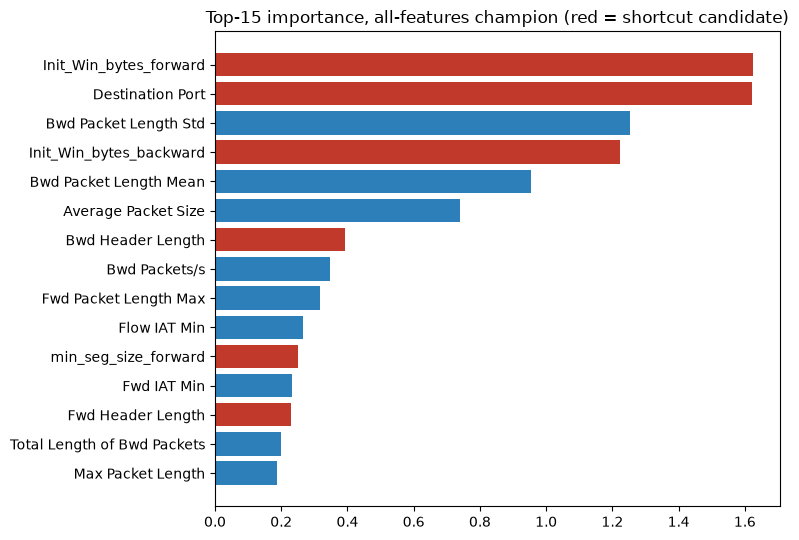

In [14]:
def tree_parts(model, Xs):
    if isinstance(model, Pipeline):
        return model[-1], np.asarray(model[:-1].transform(Xs))
    return model, Xs


def mean_abs_shap(model, Xs):
    est, Xt = tree_parts(model, Xs)
    sv = shap.TreeExplainer(est).shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return np.abs(sv).mean(0)


def importance_study(fs_name):
    name, cols, model = TREE_CHAMP[fs_name], FEATURE_SETS[fs_name], get_model(TREE_CHAMP[fs_name], fs_name)
    rng = np.random.default_rng(SEED)
    pidx = va[rng.choice(len(va), min(PERM_SAMPLE, len(va)), replace=False)]
    perm = permutation_importance(model, X.iloc[pidx][cols], y_all[pidx], scoring="average_precision",
                                  n_repeats=2, random_state=SEED, n_jobs=1).importances_mean
    perm = pd.Series(perm, index=cols)
    if SHAP_OK and name != "hgb":
        vecs = [mean_abs_shap(model, X.iloc[va[rng.choice(len(va), min(SHAP_SAMPLE, len(va)), replace=False)]][cols]) for _ in range(3)]
        V = np.vstack(vecs)
        stab = np.mean([spearmanr(V[i], V[j]).correlation for i in range(3) for j in range(i + 1, 3)])
        imp = pd.Series(V.mean(0), index=cols)
    else:
        imp, stab = perm.copy(), np.nan
        print("SHAP unavailable for this model -> permutation importance used as the ranking")
    agree = spearmanr(imp.reindex(cols), perm.reindex(cols)).correlation
    tab = pd.DataFrame({"importance": imp, "permutation_importance": perm,
                        "is_shortcut_candidate": [c in SHORTCUT_FEATURES for c in cols]}).sort_values("importance", ascending=False)
    return tab, stab, agree


IMPORTANCE = {}
for fs_name in FEATURE_SETS:
    tab, stab, agree = importance_study(fs_name)
    IMPORTANCE[fs_name] = tab
    print(f"\n=== {fs_name} | model={TREE_CHAMP[fs_name]} | SHAP rank stability (Spearman)={stab:.3f} | SHAP-vs-permutation agreement={agree:.3f}")
    print(f"share of top-10 importance mass on shortcut candidates: {tab.head(10).query('is_shortcut_candidate').importance.sum() / tab.head(10).importance.sum():.1%}")
    display(tab.head(15).round(4))
    save(tab, f"importance_{fs_name}.csv")

top = IMPORTANCE["all_features"].head(15).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top["importance"], color=["#c0392b" if s else "#2c7fb8" for s in top["is_shortcut_candidate"]])
plt.title("Top-15 importance, all-features champion (red = shortcut candidate)")
plt.tight_layout(); plt.savefig(FIGS / "importance_all_features.png", dpi=160); plt.show()

In [15]:
def reduction_experiment(fs_name):
    name, cols = TREE_CHAMP[fs_name], FEATURE_SETS[fs_name]
    model, params = get_model(name, fs_name), BEST[(name, fs_name)]
    tr_red = cap_rows(tr, fam, REDUCTION_TRAIN_ROWS)
    Xr = X.iloc[tr_red][cols]
    F, _ = f_classif(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(Xr), y_all[tr_red])
    est, _ = tree_parts(model, Xr)
    rankings = {"importance (SHAP)": IMPORTANCE[fs_name]["importance"],
                "ANOVA F": pd.Series(np.nan_to_num(F), index=cols),
                "tree gain": pd.Series(est.feature_importances_, index=cols)}
    rng, rows = np.random.default_rng(SEED), []
    full = AGG[(AGG.split == "val") & (AGG.model == name) & (AGG.features == fs_name)].iloc[0]
    full_t = AGG[(AGG.split == "test") & (AGG.model == name) & (AGG.features == fs_name)].iloc[0]
    for k in [k for k in SHAP_K_LIST if k < len(cols)]:
        sets = {m: r.sort_values(ascending=False).index[:k].tolist() for m, r in rankings.items()}
        for d in range(3):
            sets[f"random #{d}"] = rng.choice(cols, k, replace=False).tolist()
        for m, feats in sets.items():
            mdl = build_model(name, params, SEED).fit(X.iloc[tr_red][feats], y_all[tr_red])
            rv, _ = evaluate(mdl, X.iloc[va][feats], meta.iloc[va])
            rt, _ = evaluate(mdl, X.iloc[te][feats], meta.iloc[te])
            rows.append({"k": k, "method": "random" if m.startswith("random") else m, "val_mcc": rv["mcc"], "test_mcc": rt["mcc"],
                         "test_FN": rt["FN"], "test_FP": rt["FP"]})
    out = pd.DataFrame(rows).groupby(["k", "method"]).mean().reset_index()
    return out, full["mcc"], full_t["mcc"]


REDUCTION = {}
for fs_name in FEATURE_SETS:
    red, full_val, full_test = reduction_experiment(fs_name)
    REDUCTION[fs_name] = red
    ok = red[(red.method == "importance (SHAP)") & (red.val_mcc >= full_val - 0.002)].sort_values("k")
    k_sel = int(ok.iloc[0].k) if len(ok) else None
    print(f"\n=== feature reduction on '{fs_name}' ({TREE_CHAMP[fs_name]}) | full model: val MCC={full_val:.4f}, test MCC={full_test:.4f}")
    print("selected k (strict 0.002 rule on validation):", k_sel if k_sel else "none: no reduced set is within tolerance")
    display(red.pivot(index="k", columns="method", values="test_mcc").round(4))
    save(red, f"feature_reduction_{fs_name}.csv")


=== feature reduction on 'all_features' (xgb) | full model: val MCC=0.9825, test MCC=0.9981
selected k (strict 0.002 rule on validation): 10


method,ANOVA F,importance (SHAP),random,tree gain
k,,,,
5,0.8880,0.9430,0.9590,0.9635
10,0.9750,0.9963,0.9780,0.9753
20,0.9860,0.9978,0.9915,0.9888
30,0.9907,0.9979,0.9900,0.9943



=== feature reduction on 'no_shortcuts' (xgb) | full model: val MCC=0.9781, test MCC=0.9923
selected k (strict 0.002 rule on validation): none: no reduced set is within tolerance


method,ANOVA F,importance (SHAP),random,tree gain
k,,,,
5,0.8882,0.9660,0.8939,0.9591
10,0.9754,0.9728,0.9716,0.9680
20,0.9882,0.9888,0.9885,0.9819
30,0.9899,0.9881,0.9883,0.9912


## 8. Leave-one-file(day)-out: the realistic scenario estimate
Train on seven CSV files, test on the eighth. Near-copies of the held-out rows are also removed from training. Each file contains different attacks, so this simulates a **new attack scenario** and is the best proxy for real deployment available in this data variant. (Monday has no attacks, so only its false-alarm rate is meaningful.)

In [16]:
LOFO = pd.DataFrame()
if RUN_LOFO:
    rows = []
    for held in meta["file"].unique():
        hm = (meta["file"] == held).to_numpy()
        train_mask = ~hm & ~np.isin(meta["nk"].to_numpy(), meta.loc[hm, "nk"].to_numpy())
        idx_tr = cap_rows(np.flatnonzero(train_mask), fam, LOFO_TRAIN_ROWS)
        for fs_name, cols in FEATURE_SETS.items():
            name = TREE_CHAMP[fs_name]
            mdl = build_model(name, BEST[(name, fs_name)], SEED).fit(X.iloc[idx_tr][cols], y_all[idx_tr])
            r, _ = evaluate(mdl, X.loc[hm, cols], meta.loc[hm])
            rows.append({"held_out_file": held, "features": fs_name, "model": name, "n_attack": r["n_attack"],
                         "recall": r["recall"], "precision": r["precision"], "fpr": r["fpr"], "mcc": r["mcc"]})
    LOFO = pd.DataFrame(rows)
    display(LOFO.round(4)); save(LOFO, "leave_one_file_out.csv")

,held_out_file,features,model,n_attack,recall,precision,fpr,mcc
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,all_features,xgb,128013,0.6286,0.9991,0.0008,0.6465
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,no_shortcuts,xgb,128013,0.6349,0.9985,0.0013,0.6509
2,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,all_features,xgb,90255,0.0050,0.4901,0.0038,0.0086
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,no_shortcuts,xgb,90255,0.0025,0.3258,0.0039,-0.0117
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,all_features,xgb,1953,0.0000,0.0000,0.0002,-0.0015
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,no_shortcuts,xgb,1953,0.0000,0.0000,0.0005,-0.0023
6,Monday-WorkingHours.pcap_ISCX.csv,all_features,xgb,0,NaN,0.0000,0.0003,0.0000
7,Monday-WorkingHours.pcap_ISCX.csv,no_shortcuts,xgb,0,NaN,0.0000,0.0012,0.0000
8,Thursday-WorkingHours-Afternoon-Infilteration....,all_features,xgb,36,0.0000,0.0000,0.1544,-0.0052
9,Thursday-WorkingHours-Afternoon-Infilteration....,no_shortcuts,xgb,36,0.0278,0.0000,0.1367,-0.0039


## 9. External generalization: train on 2017, test on CSE-CIC-IDS2018
Same model objects trained above (no 2018 data used for fitting, thresholds or selection). Both feature sets are evaluated, so the **shortcut hypothesis is tested directly**: if removing the shortcut candidates improves 2018 performance, those features were fingerprints of the 2017 testbed. Also reported: per-family recall, the share of 2018 flows that are near-copies of 2017 training flows, and class-conditional drift (KS statistic, PSI).

In [17]:
def psi(ref, cur, bins=10):
    ref, cur = ref[np.isfinite(ref)], cur[np.isfinite(cur)]
    if len(ref) < 20 or len(cur) < 20:
        return np.nan
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0 if (ref.min() == ref.max() == cur.min() == cur.max()) else np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-6, None)
    q = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-6, None)
    return float(np.sum((q - p) * np.log(q / p)))


EXT, EXT_FAM, DRIFT = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
if RUN_EXTERNAL:
    ext_models = {fs: get_model(TREE_CHAMP[fs], fs) for fs in FEATURE_SETS}
    train_near = np.unique(meta.loc[tr, "nk"].to_numpy())
    probs = {fs: [] for fs in FEATURE_SETS}
    ys, labs, samp, confs, near_hits, total = [], [], [], [], 0, 0
    conf_set = PROFILES.get("2018", {}).get("conflict_hashes")      # vectors labeled both benign and attack in 2018
    rng = np.random.default_rng(SEED)
    for Xr, lab, fname in iter_chunks(list_csvs(RAW_2018_DIR), "2018"):
        Xc = clean_features(Xr)
        near_hits += int(np.isin(near_key(Xc, NEAR_DECIMALS), train_near).sum()); total += len(Xc)
        yb = to_binary(lab); ys.append(yb); labs.append(lab.to_numpy())
        confs.append(np.isin(row_hash(Xc), conf_set) if conf_set is not None else np.zeros(len(Xc), dtype=bool))
        for fs, mdl in ext_models.items():
            probs[fs].append(mdl.predict_proba(Xc[FEATURE_SETS[fs]])[:, 1].astype("float32"))
        keep = rng.random(len(Xc)) < min(1.0, 4 * DRIFT_PER_CLASS / 2_000_000 + 0.005)
        samp.append(Xc.loc[keep].assign(_y=yb[keep]))
    y2, l2 = np.concatenate(ys), np.concatenate(labs)
    print(f"2018 flows evaluated: {total:,} | attack share {y2.mean():.3f} | near-copies of 2017 training rows: {100 * near_hits / total:.3f}%")
    conf = np.concatenate(confs)
    print(f"rows whose feature vector carries both labels in 2018: {conf.sum():,} ({100 * conf.mean():.2f}%)")
    rows, fam_cols = [], {}
    for fs in FEATURE_SETS:
        prob = np.concatenate(probs[fs]); pred = (prob >= THRESHOLD).astype("int8")
        for subset, mask in [("all rows", np.ones(len(y2), bool)), ("without conflicting-label vectors", ~conf)]:
            rows.append({"features": fs, "subset": subset, "model": TREE_CHAMP[fs],
                         **binary_metrics(y2[mask], pred[mask], prob[mask])})
        fam_cols[f"{TREE_CHAMP[fs]}|{fs}"] = per_family_recall(l2[~conf], pred[~conf])      # per-family on clean labels
    EXT = pd.DataFrame(rows).set_index(["features", "subset"])
    EXT_FAM = pd.concat({k: v["recall"] for k, v in fam_cols.items()}, axis=1)
    EXT_FAM.insert(0, "support", next(iter(fam_cols.values()))["support"])
    print("External results (fixed threshold 0.5)")
    display(EXT[["model", "precision", "recall", "fpr", "f1", "mcc", "roc_auc", "pr_auc", "FP", "FN"]].round(4))
    print("External per-family recall (rows with conflicting labels excluded)"); display(EXT_FAM.sort_values("support", ascending=False).round(4))
    save(EXT, "external_2018_results.csv"); save(EXT_FAM, "external_2018_per_family_recall.csv")

    S = pd.concat(samp, ignore_index=True)
    rows = []
    for cls, cname in [(0, "Benign"), (1, "Attack")]:
        e = S[S._y == cls].head(DRIFT_PER_CLASS)
        s_idx = tr[y_all[tr] == cls]
        s = X.iloc[s_idx[rng.choice(len(s_idx), min(DRIFT_PER_CLASS, len(s_idx)), replace=False)]]
        for c in base_cols:
            a, b = s[c].to_numpy(float), e[c].to_numpy(float)
            a, b = a[np.isfinite(a)], b[np.isfinite(b)]
            if len(a) >= 20 and len(b) >= 20:
                rows.append({"class": cname, "feature": c, "ks": ks_2samp(a, b).statistic, "psi": psi(a, b),
                             "median_2017": np.median(a), "median_2018": np.median(b), "shortcut_candidate": c in SHORTCUT_FEATURES})
    DRIFT = pd.DataFrame(rows).sort_values(["class", "ks"], ascending=[True, False])
    print("Most drifted features per class (KS statistic; PSI > 0.25 = large shift)")
    for cname in ["Attack", "Benign"]:
        display(DRIFT[DRIFT["class"] == cname].head(12).round(3))
    print("Share of the 15 most drifted features that are shortcut candidates:",
          DRIFT.groupby("class").head(15).groupby("class").shortcut_candidate.mean().round(2).to_dict())
    save(DRIFT, "external_2018_feature_drift.csv")
else:
    print("External section skipped: 2018 folder not found.")

2018 flows evaluated: 16,232,943 | attack share 0.169 | near-copies of 2017 training rows: 5.041%
rows whose feature vector carries both labels in 2018: 1,239,471 (7.64%)
External results (fixed threshold 0.5)


model  precision  recall     fpr      f1     mcc  roc_auc  pr_auc      FP       FN
features     subset                                                                                                              
all_features all rows                            xgb     0.9783  0.0777  0.0004  0.1439  0.2518   0.7828  0.6630    4732  2534781
             without conflicting-label vectors   xgb     0.9784  0.0803  0.0004  0.1483  0.2548   0.7913  0.6798    4715  2445981
no_shortcuts all rows                            xgb     0.4091  0.1029  0.0303  0.1645  0.1349   0.8304  0.4173  408612  2465364
             without conflicting-label vectors   xgb     0.4090  0.1063  0.0331  0.1687  0.1333   0.8353  0.4277  408398  2376760

External per-family recall (rows with conflicting labels excluded)


,support,xgb|all_features,xgb|no_shortcuts
label,,,
DDOS attack-HOIC,686012,0.0000,0.0000
DDoS attacks-LOIC-HTTP,576191,0.0000,0.4546
DoS attacks-Hulk,461912,0.3231,0.0000
Bot,286191,0.0000,0.0021
FTP-BruteForce,193360,0.1275,0.0000
SSH-Bruteforce,187589,0.0001,0.0000
DoS attacks-SlowHTTPTest,139890,0.1740,0.0000
Infilteration,73124,0.0008,0.0167
DoS attacks-GoldenEye,41508,0.1824,0.2432


Most drifted features per class (KS statistic; PSI > 0.25 = large shift)


,class,feature,ks,psi,median_2017,median_2018,shortcut_candidate
87,Attack,Flow IAT Max,0.704,8.672,5023291.500,613.000,False
70,Attack,Flow Duration,0.699,8.040,6522169.000,613.000,False
86,Attack,Flow IAT Std,0.697,6.357,2111617.500,0.000,False
103,Attack,Fwd Packets/s,0.696,7.861,0.875,3262.643,False
84,Attack,Flow Packets/s,0.677,7.317,1.087,3262.643,False
85,Attack,Flow IAT Mean,0.671,7.254,1096601.188,612.000,False
91,Attack,Fwd IAT Std,0.656,5.574,2040485.688,0.000,False
127,Attack,Init_Win_bytes_backward,0.623,4.429,229.000,0.000,True
106,Attack,Max Packet Length,0.608,13.588,4344.000,0.000,False
107,Attack,Packet Length Mean,0.608,9.989,777.933,0.000,False


,class,feature,ks,psi,median_2017,median_2018,shortcut_candidate
60,Benign,min_seg_size_forward,0.480,4.388,20.0,20.000,True
33,Benign,Bwd Header Length,0.365,1.709,40.0,20.000,True
7,Benign,Fwd Packet Length Min,0.298,0.477,6.0,0.000,False
36,Benign,Min Packet Length,0.292,0.496,6.0,0.000,False
20,Benign,Fwd IAT Total,0.289,1.119,4.0,93147.000,False
23,Benign,Fwd IAT Max,0.289,1.269,4.0,70822.000,False
21,Benign,Fwd IAT Mean,0.287,1.479,4.0,48564.111,False
32,Benign,Fwd Header Length,0.286,2.849,64.0,52.000,True
19,Benign,Flow IAT Min,0.279,0.517,4.0,60.000,False
11,Benign,Bwd Packet Length Min,0.272,0.465,6.0,0.000,False


Share of the 15 most drifted features that are shortcut candidates: {'Attack': 0.07, 'Benign': 0.27}


## 10. Findings (auto-generated from the executed results)
The numbers below are computed, not typed. Read them as the answer to the central question: *how much of the headline accuracy survives a leak-free split, a new-scenario test and a new dataset?*

In [18]:
def champ_row(split_name, fs):
    return AGG[(AGG.split == split_name) & (AGG.model == TREE_CHAMP[fs]) & (AGG.features == fs)].iloc[0]

summary = []
for fs in FEATURE_SETS:
    t = champ_row("test", fs)
    row = {"features": fs, "model": TREE_CHAMP[fs], "internal_test_MCC": t.mcc,
           "internal_MCC_95CI": f"[{t.mcc_ci_low:.4f}, {t.mcc_ci_high:.4f}]", "internal_recall": t.recall, "internal_FPR": t.fpr}
    if len(LOFO):
        L = LOFO[(LOFO.features == fs) & (LOFO.n_attack > 0)]
        row["leave_one_file_out_mean_recall"] = L.recall.mean()
        row["leave_one_file_out_mean_MCC"] = L.mcc.mean()
    if len(EXT):
        e_all, e_cln = EXT.loc[(fs, "all rows")], EXT.loc[(fs, "without conflicting-label vectors")]
        row.update({"external_recall": e_all["recall"], "external_MCC": e_all["mcc"], "external_ROC_AUC": e_all["roc_auc"],
                    "external_recall_clean": e_cln["recall"], "external_MCC_clean": e_cln["mcc"], "external_ROC_AUC_clean": e_cln["roc_auc"]})
    summary.append(row)
SUMMARY = pd.DataFrame(summary).set_index("features")
display(SUMMARY.round(4)); save(SUMMARY, "headline_summary.csv")

a, n = SUMMARY.loc["all_features"], SUMMARY.loc["no_shortcuts"]
print("\nAUTOMATIC READING OF THE RESULTS")
print(f"- Duplicates and conflicts: removed {DEDUP['exact_duplicate_rows_removed']:,} duplicate and {DEDUP['conflicting_label_rows_removed']:,} conflicting rows; "
      f"split audit = 0 shared vectors; adversarial AUC = {ADV_AUC:.3f}.")
if len(SPLIT_VAR):
    sv = SPLIT_VAR[SPLIT_VAR.part == "test"].groupby("features")["recall"].agg(["min", "max"])
    print("- Split variance (test recall across different group splits): " + "; ".join(f"{f}: {r['min']:.4f}-{r['max']:.4f}" for f, r in sv.iterrows()) + ". Model differences smaller than this spread are not meaningful.")
print(f"- Leak-free internal test, all features: MCC {a.internal_test_MCC:.4f} {a.internal_MCC_95CI}; without shortcut candidates: MCC {n.internal_test_MCC:.4f}.")
if len(LOFO):
    print(f"- New-scenario test (leave-one-file-out), mean attack recall: all features {a.leave_one_file_out_mean_recall:.3f} vs no shortcuts {n.leave_one_file_out_mean_recall:.3f}.")
if len(EXT):
    print(f"- New-dataset test (2018), all features vs no shortcuts: recall {a.external_recall:.3f} vs {n.external_recall:.3f}; "
          f"MCC {a.external_MCC:.3f} vs {n.external_MCC:.3f}; ROC-AUC {a.external_ROC_AUC:.3f} vs {n.external_ROC_AUC:.3f}.")
    if n.external_MCC > a.external_MCC + 0.02:
        print("  => Removing the shortcut candidates IMPROVES 2018 performance: the model was relying on 2017-specific fingerprints.")
    elif a.external_MCC > n.external_MCC + 0.02:
        print("  => The candidate features still help on 2018, so they are not pure shortcuts. The weak transfer has another cause (feature drift, different attack tools or label noise).")
    else:
        print("  => Removing the candidates changes 2018 performance little: the transfer gap is mainly driven by feature drift / attack differences, not by these six features.")
    print(f"  (excluding the 2018 vectors that carry both labels: recall {a.external_recall_clean:.3f} vs {n.external_recall_clean:.3f}; "
          f"MCC {a.external_MCC_clean:.3f} vs {n.external_MCC_clean:.3f})")
    if a.external_ROC_AUC < 0.9:
        print("  => ROC-AUC is low: the ranking itself degraded, so no threshold choice can repair the transfer.")

,model,internal_test_MCC,internal_MCC_95CI,internal_recall,internal_FPR,leave_one_file_out_mean_recall,leave_one_file_out_mean_MCC,external_recall,external_MCC,external_ROC_AUC,external_recall_clean,external_MCC_clean,external_ROC_AUC_clean
features,,,,,,,,,,,,,
all_features,xgb,0.9981,"[0.9977, 0.9983]",0.9982,0.0003,0.1320,0.1835,0.0777,0.2518,0.7828,0.0803,0.2548,0.7913
no_shortcuts,xgb,0.9923,"[0.9918, 0.9928]",0.9900,0.0006,0.1028,0.1245,0.1029,0.1349,0.8304,0.1063,0.1333,0.8353



AUTOMATIC READING OF THE RESULTS
- Duplicates and conflicts: removed 325,494 duplicate and 7,144 conflicting rows; split audit = 0 shared vectors; adversarial AUC = 0.543.
- Split variance (test recall across different group splits): all_features: 0.9981-0.9986; no_shortcuts: 0.9900-0.9927. Model differences smaller than this spread are not meaningful.
- Leak-free internal test, all features: MCC 0.9981 [0.9977, 0.9983]; without shortcut candidates: MCC 0.9923.
- New-scenario test (leave-one-file-out), mean attack recall: all features 0.132 vs no shortcuts 0.103.
- New-dataset test (2018), all features vs no shortcuts: recall 0.078 vs 0.103; MCC 0.252 vs 0.135; ROC-AUC 0.783 vs 0.830.
  => The candidate features still help on 2018, so they are not pure shortcuts. The weak transfer has another cause (feature drift, different attack tools or label noise).
  (excluding the 2018 vectors that carry both labels: recall 0.080 vs 0.106; MCC 0.255 vs 0.133)
  => ROC-AUC is low: the ranking its

### Suggested wording for the paper (fill in after the run)
1. **Headline claim.** Report the *leak-free grouped* test score and the *leave-one-file-out* score, not a random-split score. State the number of duplicate and conflicting rows removed.
2. **Shortcut finding.** Report the all-features vs no-shortcut comparison on all three evaluations (grouped test, leave-one-file-out, 2018).
3. **Model comparison.** Use the multi-seed mean ± std and the bootstrap CI. If intervals overlap, say the models are statistically indistinguishable.
4. **Explainability.** Report SHAP stability and the controls (ANOVA / gain / random). Only claim SHAP-guided reduction is useful if it beats them.
5. **Limitations.** MachineLearningCVE variant (no sessions or timestamps), feature-based grouping, known label noise in both datasets, binary task only, no zero-day or real-time claim.

## 11. Manifest and artifacts

In [19]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)

MANIFEST = {
    "notebook": "CIC-IDS2017 v4 leakage-safe", "smoke_mode": SMOKE, "seed": SEED, "final_seeds": FINAL_SEEDS,
    "xgboost_device_requested": XGB_DEVICE_REQUESTED, "xgboost_device_used": XGB_DEVICE,
    "near_duplicate_decimals": NEAR_DECIMALS, "split_fractions": SPLIT_FRACTIONS, "threshold": THRESHOLD,
    "tune_rows": int(len(idx_tune)), "cv": f"GroupKFold({CV_FOLDS})", "dedup": DEDUP,
    "split_sizes": {"train": len(tr), "val": len(va), "test": len(te)}, "adversarial_auc": float(ADV_AUC),
    "constant_features_dropped": constant, "shortcut_candidates": SHORTCUT_FEATURES,
    "best_params": {f"{k[0]}|{k[1]}": v for k, v in BEST.items()},
    "tree_champions": TREE_CHAMP, "overall_validation_champion": OVERALL_CHAMP,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__,
                 "xgboost": xgb.__version__ if XGB_OK else None, "shap": shap.__version__ if SHAP_OK else None},
}
(TABLES / "experiment_manifest.json").write_text(json.dumps(MANIFEST, indent=2, default=jsonable), encoding="utf-8")
for fs in FEATURE_SETS:
    joblib.dump({"model": get_model(TREE_CHAMP[fs], fs), "features": FEATURE_SETS[fs], "threshold": THRESHOLD,
                 "target": {"BENIGN": 0, "ATTACK": 1}}, MODELS_DIR / f"champion_{fs}.joblib", compress=3)
print("Saved tables, figures, manifest and champion models in", OUT_DIR.resolve())

Saved tables, figures, manifest and champion models in E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\research_outputs_v4


## References
- Engelen, G., Rimmer, V., Joosen, W. (2021). *Troubleshooting an Intrusion Detection Dataset: the CICIDS2017 Case Study.*
- Liu, L. et al. (2022). *Error Prevalence in NIDS Datasets: A Case Study on CIC-IDS-2017 and CSE-CIC-IDS-2018.*
- Arp, D. et al. (2022). *Dos and Don'ts of Machine Learning in Computer Security.* USENIX Security.
- Sharafaldin, I., Lashkari, A. H., Ghorbani, A. A. (2018). *Toward Generating a New Intrusion Detection Dataset and Intrusion Traffic Characterization.* ICISSP.
- Lundberg, S. M., Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.